In [12]:
%load_ext autoreload
%autoreload 2

import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import CoolProp.CoolProp as CP
import thermo as thermo
import time as timer
import cProfile
import pstats
import yaml
import copy
import sys
from scipy.optimize import brentq
from thermal import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
# HeatingElement and TinlessSimulation have been extracted to
# thermal/tinless.py and are imported via `from thermal import *`.
# This cell is intentionally left as a stub — do NOT redefine the
# classes here, as running this cell would overwrite the package
# version for the remainder of the kernel session.


In [23]:
yaml_content = """
# Tinless System Model - Simulation Input
# Graphite storage block radiating directly to a central powerstick (no tin piping)

# -- General Simulation Parameters --------------------------------------------
end_time: 240000          # total simulation time [s]  (50 hr discharge)
dt_short: 60              # timestep [s] — used for the first dt_short_duration seconds
dt_medium: 600             # timestep [s] — used when shade is active and not clamped
dt_long: 1200               # timestep [s] — used when shade is clamped at f_shade_max
dt_short_duration: 3600    # seconds of real time to use dt_short at the start
sub_steps: 5              # FD sub-steps per time step (stability)
T_sur: 300                # surroundings temperature [K]
block_heat_loss_bool: False
liner_bool: True         # True = TaC liner, False = no liner
liner_material: graphite      # tac = TaC-coated inner face; graphite = uncoated graphite
shade_bool: True       # True = insulating graphite shade, False = no shade
print_outputs_bool: True

# -- Emissivity Table ---------------------------------------------------------
# Format per band: [[wl_min, wl_max], emis_active, emis_bare, emis_inactive]
# Use range format to allow time-varying tables (e.g. panels offline during charging)
emissivity_tables:
  - range: [0, end_time-1]
    value:
      - [[0.1, 1.24], 0.9, 0.02, 0.02]   # below bandgap
      - [[1.24, 20.0], 0.015, 0.02, 0.02]  # above bandgap

# -- Storage Block ------------------------------------------------------------
storage:
  avg_flux: 7.5            # average power density to extract [W/cm^2]
  duration_hr: 50          # discharge duration [hr]
  T_min: 1873              # minimum (empty) block temperature [K]
  block_temp_range: 800    # operating temperature swing [K]
  L: 8                   # axial length [m]
  th_ins: 0.0              # outer-wall insulation thickness [m]
  num_ax_segments: 3
  num_rad_segments: 10

# -- Powerstick ---------------------------------------------------------------
powerstick:
  side_len: 0.26           # square cross-section side length [m]
  area_ratio: 5            # D_in / D_ps_eff
  cooling_temp: 323        # powerstick cooling temperature [K]
  f_bare: 0.05
  f_active: .9
  liner_side_len: 0.5     # square side length of liner [m]; r_liner = 2*side_len/pi
  liner_thickness: 0.005  # liner wall thickness [m]
  tungsten_foil: false   # add W foil between TaC face and powerstick

# -- Insulating Shade -------------------------------------------------------
# Octagonal shade surrounding the liner.
# liner_to_shade_perimeter_ratio = shade_perimeter / liner_perimeter
# r_shade_eff = ratio * 2 * liner_side_len / pi  (equivalent circular radius)
# f_shade is found by bisection to hold cell flux at storage.avg_flux.
# shade_bool=False disables the shade.
shade:
  liner_to_shade_perimeter_ratio: 1.707  # 1 + sqrt(2)/2; octagon with L = liner_side_len
  thickness: 0.0391          # shade wall thickness [m]
  surface_emissivity: 0.9         # emissivity of shade surfaces
  num_conduction_layers: 5 # number of layers for 1-D conduction model through shade
  corner_gap: 0.003175     # gap between adjacent panel edges at fully-closed [m] (= 1/8 in)
  outer_foil: false          # true = W foil on shade outer face (adds radiative resistance)
  
# -- Heater ------------------------------------------------------------------
# Central cylindrical resistive heating element used during charging.
# Phase 1: max_power supplied; T_heater rises as graphite warms.
# Phase 2: T_heater reaches max_temperature; power reduces to hold that temp.
# Heating stops when block T_avg reaches T_min + block_temp_range.
heater:
  side_len: 0.15            # m   (heater rod side length)
  area_ratio: 8.75           # D_in / D_heater  (controls heater-to-inner-wall gap)
  max_temperature: 2873     # K   (maximum heater surface temperature)
  max_power: 400000         # W   (maximum electrical power input)
  emissivity: 0.85           # gray-body emissivity of heater surface
"""

with open('tinless_model_input.yaml', 'w') as f:
    f.write(yaml_content)

print('Wrote tinless_model_input.yaml')


Wrote tinless_model_input.yaml


In [24]:
# ── Load inputs ───────────────────────────────────────────────────────────────
with open('tinless_model_input.yaml') as f:
    cfg = yaml.safe_load(f)

end_time             = cfg['end_time']
dt_short             = cfg['dt_short']
dt_medium            = cfg['dt_medium']
dt_long              = cfg['dt_long']
dt_short_duration    = cfg.get('dt_short_duration', 3600)
sub_steps            = cfg['sub_steps']
T_sur                = cfg['T_sur']
liner_bool           = cfg['liner_bool']
liner_material       = cfg.get('liner_material', 'tac')
block_heat_loss_bool = cfg['block_heat_loss_bool']

# Emissivity table — parse first range entry (extend here for time-varying tables)
raw_emis = cfg['emissivity_tables'][0]['value']
emissivity_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
                     for row in raw_emis]

# ── Storage block geometry ────────────────────────────────────────────────────
s = cfg['storage']
avg_flux         = s['avg_flux']
duration_hr      = s['duration_hr']
T_min            = s['T_min']
block_temp_range = s['block_temp_range']
L                = s['L']
th_ins           = s['th_ins']
num_ax           = s['num_ax_segments']
num_rad          = s['num_rad_segments']

# ── Powerstick geometry ───────────────────────────────────────────────────────
p = cfg['powerstick']
side_len       = p['side_len']
area_ratio     = p['area_ratio']
f_bare         = p['f_bare']
f_active       = p['f_active']
T_ps           = p['cooling_temp']
liner_side_len    = p['liner_side_len']
liner_thickness      = p.get('liner_thickness', 0.0)
liner_tungsten_foil  = p.get('tungsten_foil', False)

sh                = cfg.get('shade', {})
shade_bool       = sh.get('shade_bool', cfg.get('shade_bool', False))
liner_to_shade_ratio        = sh.get('liner_to_shade_perimeter_ratio', None)
# shade_side_len: equivalent circular radius = ratio * 2 * liner_side_len / pi
shade_side_len              = liner_to_shade_ratio * liner_side_len if liner_to_shade_ratio else None
shade_thickness             = sh.get('thickness', 0.05)
shade_surface_emissivity = sh.get('surface_emissivity', 0.8)
shade_outer_foil               = sh.get('outer_foil', False)
shade_num_conduction_layers = sh.get('num_conduction_layers', 5)
corner_gap                   = sh.get('corner_gap', 0.003175)
_shade_perimeter            = liner_to_shade_ratio * 4 * liner_side_len if liner_to_shade_ratio else None
# f_shade geometry: panels fully open → only edge (thickness) visible
#                    panels fully closed → only corner gaps pass light
f_shade_min      = 8 * shade_thickness / _shade_perimeter  if _shade_perimeter else 0.03
f_shade_max      = 1 - 8 * corner_gap   / _shade_perimeter  if _shade_perimeter else 0.99

r_ps_eff = 2 * side_len / np.pi
r_in     = r_ps_eff * area_ratio
A_ps    = 4 * side_len * L  # cylindrical equiv area of entire stick (radiation absorbed by all areas)
T_max   = T_min + block_temp_range
T_init  = T_max
T_avg_  = T_min + block_temp_range / 2
f_cell_     = (1.0 - f_bare) * f_active
f_inact_    = (1.0 - f_bare) * (1.0 - f_active)
ps_tmp_ = PowerStick(axial_steps=1, width=side_len, height=L,
cooling_temp=T_ps,
f_bare=f_bare, f_active=f_active,
liner_bool=liner_bool, liner_width=liner_side_len,
emissivity_table=emissivity_table)
inc_bins_, _, _ = ps_tmp_.incident_energy(T_min-100, 1 / area_ratio)
inc_tot_= sum(inc_bins_.values())
f_Q_        = sum(
    inc_bins_[row[0]] / inc_tot_ * f_cell_ * row[1]
    / (f_bare * row[2] + f_cell_ * row[1] + f_inact_ * row[3])
    for row in emissivity_table)
E_req   = avg_flux * 1e4 * A_ps * f_cell_ / f_Q_ * duration_hr * 3600
e_dens  = storage_rho(T_avg_) * storage_cp(T_avg_) * block_temp_range
V_block = E_req / e_dens
r_out    = np.sqrt(V_block / (np.pi * L) + r_in**2)

print(f"Block: r_in={r_in:.3f} m  r_out={r_out:.3f} m  L={L} m  V={V_block:.2f} m^3")
print(f"VF = r_ps_eff/r_in = {r_ps_eff/r_in:.4f}  |  T_init = {T_init} K")

# ── Shade / liner geometry auto-correction ────────────────────────────────────
# Enforces two constraints from the shade panel opening geometry (square liners):
#   (b) r_in >= (1+sqrt(2)) * r_liner  — cavity large enough for liner+shade system
#   (a) shade_side_len >= (1+sqrt(2)/2) * liner_side_len  — panels clear liner corners
# Auto-reduces liner_side_len if (b) fails; auto-increases shade_side_len if (a) fails.
if shade_bool and liner_bool:
    _r_liner_chk = 2 * liner_side_len / np.pi
    _r_in_min    = (1.0 + np.sqrt(2)) * _r_liner_chk + 0.01
    print("r_in = {:.3f} m  |  r_in_min = {:.3f} m  |  liner_side_len = {:.3f} m".format(
        r_in, _r_in_min, liner_side_len))
    if r_in < _r_in_min:
        r_in       = _r_in_min
        area_ratio = r_in / r_ps_eff
        r_out      = np.sqrt(V_block / (np.pi * L) + r_in**2)
        print(f"[geometry] r_in increased to {r_in*1e3:.1f} mm "
              f"(area_ratio={area_ratio:.3f}, r_out={r_out:.3f} m)")
    _shade_side_min = (1.0 + np.sqrt(2) / 2.0) * liner_side_len
    if shade_side_len is None or shade_side_len < _shade_side_min:
        shade_side_len = _shade_side_min
        print(f"[geometry] shade_side_len auto-set to {shade_side_len*1e3:.1f} mm "
              f"(minimum = (1+√2/2) × {liner_side_len*1e3:.1f} mm)")
    # Recompute f_shade open/closed limits with corrected shade_side_len
    _shade_perimeter = 4.0 * shade_side_len
    f_shade_min = 8.0 * shade_thickness / _shade_perimeter
    f_shade_max = 1.0 - 8.0 * corner_gap / _shade_perimeter

# ── Build components ──────────────────────────────────────────────────────────
initial_temp_dist = np.full((num_ax, num_rad), float(T_init))
block = GraphiteBlock(
    initial_temp_distribution=initial_temp_dist,
    inner_radius=r_in, outer_radius=r_out, length=L, th_ins=th_ins,
)
dummy_pipe = Pipe(OD=0.02, length=L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
storage = StorageModule(
    N_pipes=1, Pipe=dummy_pipe, Block=block,
    num_ax_segments=num_ax, num_rad_segments=num_rad, bypass_range=[0, 1],
)
powerstick = PowerStick(
    axial_steps=num_ax, width=side_len, height=L,
    cooling_temp=T_ps,
    f_bare=f_bare, f_active=f_active,
    liner_bool=liner_bool, liner_width=liner_side_len,
    emissivity_table=emissivity_table,
)

# ── Deposition geometry ──────────────────────────────────────────────────────
r_liner_eff = 2 * liner_side_len / np.pi
if liner_bool:
    d_dep          = r_liner_eff - r_ps_eff
    area_ratio_dep = r_liner_eff / r_ps_eff
else:
    d_dep          = r_in - r_ps_eff
    area_ratio_dep = r_in / r_ps_eff  # = area_ratio from YAML

if liner_tungsten_foil:
    surf_mat = 'tungsten'
elif liner_bool and liner_material == 'tac':
    surf_mat = 'tac'
else:
    surf_mat = 'graphite'

th_w_dep = p.get('tungsten_foil_thickness', 25e-6) if liner_tungsten_foil else 0.0

dep_kwargs = dict(
    T_ps             = T_ps,
    d                = d_dep,
    area_ratio       = area_ratio_dep,
    surface_material = surf_mat,
    th_tac           = liner_thickness,
    th_w             = th_w_dep,
)

# ── Run ───────────────────────────────────────────────────────────────────────
sim = TinlessSimulation(storage, powerstick, T_sur=T_sur, block_heat_loss=block_heat_loss_bool,
                        shade_bool=shade_bool, shade_side_len=shade_side_len,
                        shade_thickness=shade_thickness,
                        shade_surface_emissivity=shade_surface_emissivity,
                        shade_outer_foil=shade_outer_foil,
                        shade_num_conduction_layers=shade_num_conduction_layers,
                        f_shade_min=f_shade_min, f_shade_max=f_shade_max,
                        nominal_cell_flux=avg_flux,
                        liner_material=liner_material,
                        liner_thickness=liner_thickness,
                        liner_tungsten_foil=liner_tungsten_foil)

results = sim.run_simulation(
    end_time          = end_time,
    dt_short          = dt_short,
    dt_medium         = dt_medium,
    dt_long           = dt_long,
    sub_steps         = sub_steps,
    dt_short_duration = dt_short_duration,
    snap_every        = 600,
    print_interval    = 600,
    deposition_fn     = deposition_rate_tinless,
    deposition_kwargs = dep_kwargs,
    T_ps_cutoff       = T_min,
)

# ── Save ──────────────────────────────────────────────────────────────────────
np.savez_compressed(
    'tinless_results.npz',
    time           = results['time'],
    Q_rad          = results['Q_rad'],
    P_elec         = results['P_elec'],
    T_avg          = results['T_avg'],
    T_inner        = results['T_inner'],
    T_outer        = results['T_outer'],
    snap_times     = results['snap_times'],
    temp_snapshots = results['temp_snapshots'],
)
print(f"\nSaved {len(results['snap_times'])} temp snapshots, "
      f"{len(results['time'])} time steps  ->  tinless_results.npz")




Block: r_in=0.828 m  r_out=1.550 m  L=8 m  V=43.20 m^3
VF = r_ps_eff/r_in = 0.2000  |  T_init = 2673 K
r_in = 0.828 m  |  r_in_min = 0.778 m  |  liner_side_len = 0.500 m
[geometry] shade_side_len auto-set to 853.6 mm (minimum = (1+√2/2) × 500.0 mm)
t=0.02 hr  T_avg=2673 K  Q_cell=661.3 kW  f_sh=0.993  dt=60 s
t=0.18 hr  T_avg=2668 K  Q_cell=631.6 kW  f_sh=0.993  dt=60 s
t=0.35 hr  T_avg=2664 K  Q_cell=613.9 kW  f_sh=0.993  dt=60 s
t=0.52 hr  T_avg=2661 K  Q_cell=601.0 kW  f_sh=0.993  dt=60 s
t=0.68 hr  T_avg=2657 K  Q_cell=590.7 kW  f_sh=0.993  dt=60 s
t=0.85 hr  T_avg=2654 K  Q_cell=582.0 kW  f_sh=0.993  dt=60 s
t=1.02 hr  T_avg=2650 K  Q_cell=574.4 kW  f_sh=0.993  dt=60 s
t=1.18 hr  T_avg=2647 K  Q_cell=567.7 kW  f_sh=0.993  dt=60 s
t=1.35 hr  T_avg=2644 K  Q_cell=561.7 kW  f_sh=0.993  dt=60 s
t=1.52 hr  T_avg=2641 K  Q_cell=556.2 kW  f_sh=0.993  dt=60 s
t=1.68 hr  T_avg=2637 K  Q_cell=551.2 kW  f_sh=0.993  dt=60 s
t=1.85 hr  T_avg=2634 K  Q_cell=546.6 kW  f_sh=0.993  dt=60 s
t=2.02 


T_inner - T_avg at SOC milestones:
  SOC = 75%  (t = 11.9 hr)  T_inner - T_avg = -119.0 K  (T_inner = 2080 C, T_avg = 2199 C)
  SOC = 50%  (t = 24.6 hr)  T_inner - T_avg = -119.2 K  (T_inner = 1880 C, T_avg = 1999 C)
  SOC = 25%  (t = 37.2 hr)  T_inner - T_avg = -119.2 K  (T_inner = 1680 C, T_avg = 1799 C)
  SOC = 0%  (t = 52.7 hr)  T_inner - T_avg = -46.5 K  (T_inner = 1553 C, T_avg = 1600 C)
Total thermal energy absorbed:   27.748 MWhr
Total electrical energy generated: 12.273 MWhr
Overall efficiency:              44.23%
Discharge time (T_avg → T_min):  52.0667 hr  (187440 s  = 3124.0 min)
Integrated C deposition on PS:   0.00 nm
Integrated metal deposition:     0.0000 nm
Total deposition on PS:          0.00 nm
  →  5-yr deposition (65.7 cycles/yr):  0.0 nm  (0.000 µm)
  → 30-yr deposition (65.7 cycles/yr):  0.1 nm  (0.000 µm)


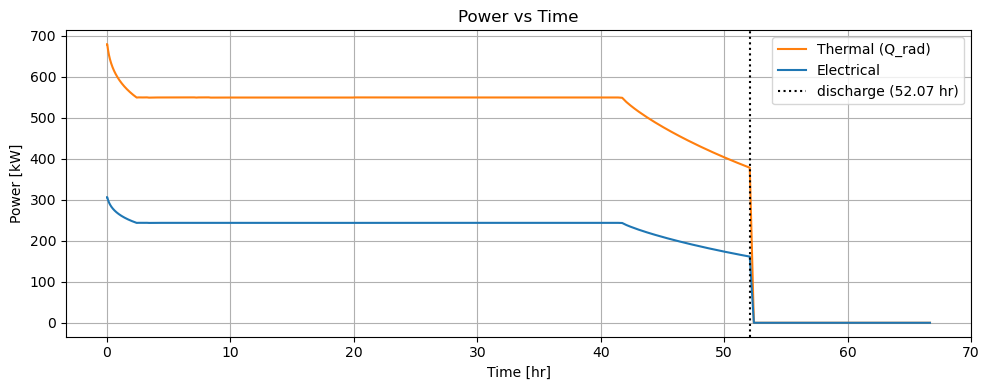

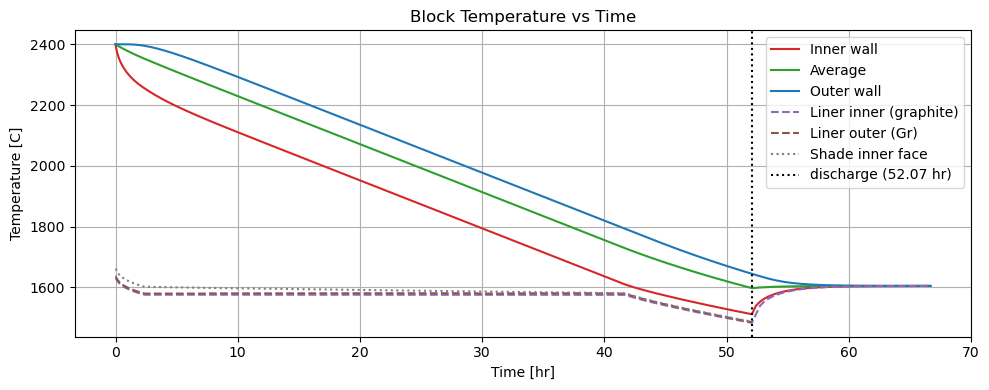

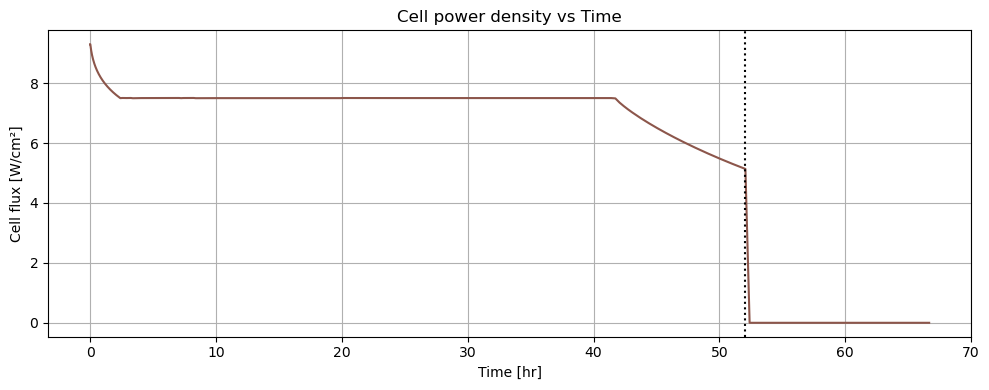

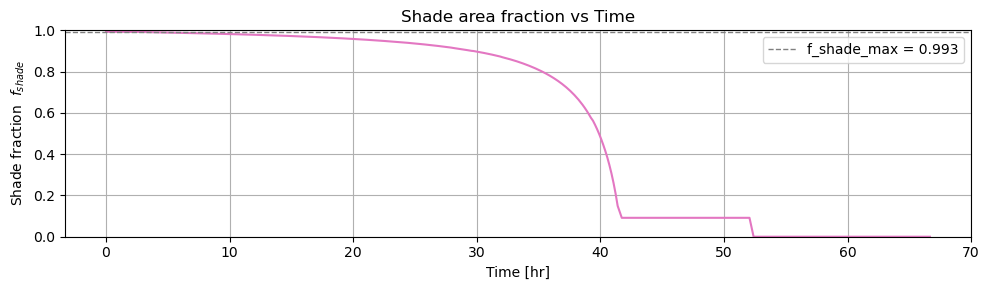

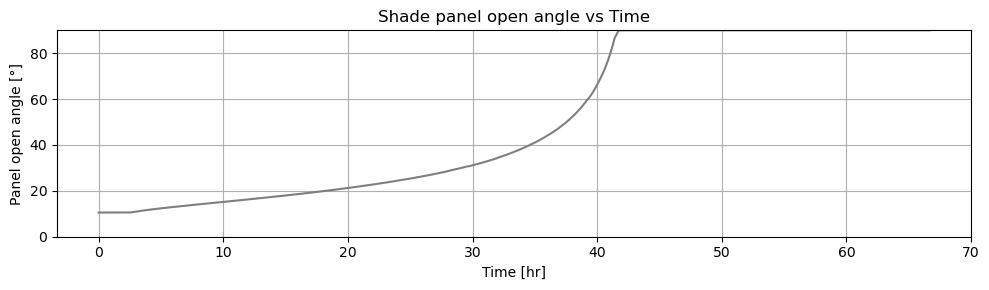

In [25]:
from scipy.integrate import cumulative_trapezoid

time_hr  = results['time'] / 3600
_t_dis_hr = results['t_ps_removed'] / 3600 if results.get('t_ps_removed') is not None else None
# -- State of charge analysis ------------------------------------------------
soc = (results['T_avg'] - T_min) / (T_max - T_min)

print()
print('T_inner - T_avg at SOC milestones:')
for target in [0.75, 0.50, 0.25, 0]:
    idx  = np.argmin(np.abs(soc - target))
    Ti   = results['T_inner'][idx]
    Ta   = results['T_avg'][idx]
    dT   = Ti - Ta
    t_hr = results['time'][idx] / 3600
    print(f'  SOC = {target*100:.0f}%  (t = {t_hr:.1f} hr)  '
          f'T_inner - T_avg = {dT:.1f} K  '
          f'(T_inner = {Ti-273.15:.0f} C, T_avg = {Ta-273.15:.0f} C)')
# -- Power vs time ------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(time_hr, results['Q_rad'] / 1e3, label='Thermal (Q_rad)', color='C1')
ax1.plot(time_hr, results['P_elec'] / 1e3, label='Electrical', color='C0')
ax1.set_xlabel('Time [hr]')
#ax1.set_xscale('log')
ax1.set_ylabel('Power [kW]')
ax1.set_title('Power vs Time')
ax1.legend()
ax1.grid(True)
if _t_dis_hr is not None:
    ax1.axvline(_t_dis_hr, color='k', ls=':', lw=1.5, label=f'discharge ({_t_dis_hr:.2f} hr)')
    ax1.legend()
fig1.tight_layout()

# -- Block temperature vs time ------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(10, 4))
ax2.plot(time_hr, results['T_inner'] - 273.15, label='Inner wall', color='C3')
ax2.plot(time_hr, results['T_avg']   - 273.15, label='Average',    color='C2')
ax2.plot(time_hr, results['T_outer'] - 273.15, label='Outer wall', color='C0')
if results['T_liner'].any():
    ax2.plot(time_hr, results['T_liner'] - 273.15,
             label=f'Liner inner ({liner_material})', color='C4', linestyle='--')
if results.get('T_liner_out') is not None and np.any(np.isfinite(results['T_liner_out'])):
    ax2.plot(time_hr, results['T_liner_out'] - 273.15,
             label='Liner outer (Gr)', color='C5', linestyle='--')
if results.get('T_foil_inner') is not None and np.any(np.isfinite(results['T_foil_inner'])):
    ax2.plot(time_hr, results['T_foil_inner'] - 273.15,
             label='W foil', color='C6', linestyle='-.')
if results.get('T_sh_out') is not None and np.any(np.isfinite(results['T_sh_out'])):
    ax2.plot(time_hr, results['T_sh_out'] - 273.15,
             label='Shade inner face', color='C7', linestyle=':')
ax2.set_xlabel('Time [hr]')
#ax2.set_xscale('log')
ax2.set_ylabel('Temperature [C]')
ax2.set_title('Block Temperature vs Time')
ax2.legend()
ax2.grid(True)
if _t_dis_hr is not None:
    ax2.axvline(_t_dis_hr, color='k', ls=':', lw=1.5, label=f'discharge ({_t_dis_hr:.2f} hr)')
    ax2.legend()
fig2.tight_layout()

# -- Cumulative electrical / thermal energy -----------------------------------
cum_Q = cumulative_trapezoid(results['Q_rad'],  results['time'], initial=0)
cum_P = cumulative_trapezoid(results['P_elec'], results['time'], initial=0)
with np.errstate(divide='ignore', invalid='ignore'):
    cum_eff = np.where(cum_Q > 0, cum_P / cum_Q * 100, 0.0)


total_Q = cum_Q[-1]
total_P = cum_P[-1]
print(f"Total thermal energy absorbed:   {total_Q/3.6e9:.3f} MWhr")
print(f"Total electrical energy generated: {total_P/3.6e9:.3f} MWhr")
print(f"Overall efficiency:              {total_P/total_Q*100:.2f}%")
if _t_dis_hr is not None:
    print(f"Discharge time (T_avg \u2192 T_min):  {_t_dis_hr:.4f} hr  ({results['t_ps_removed']:.0f} s  = {_t_dis_hr*60:.1f} min)")
if results.get('dep_total_nm', 0) > 0:
    print(f"Integrated C deposition on PS:   {results['dep_C_nm']:.2f} nm")
    print(f"Integrated metal deposition:     {results['dep_metal_nm']:.4f} nm")
    print(f"Total deposition on PS:          {results['dep_total_nm']:.2f} nm")
    _t_sim       = results['time'][-1]           # one discharge [s]
    _cycle_time  = 2 * _t_sim                    # discharge + charge [s]
    _cycles_per_yr = 3.154e7 / _cycle_time
    for _yrs in (5, 30):
        _dep_nm = results['dep_total_nm'] * _cycles_per_yr * _yrs
        print(f"  → {_yrs:2d}-yr deposition ({_cycles_per_yr:.1f} cycles/yr):  {_dep_nm:.1f} nm  ({_dep_nm/1e3:.3f} µm)")

# -- Cell flux vs time ------------------------------------------------------
_cell_area_cm2 = 4 * side_len * L * (1 - f_bare) * f_active * 1e4  # cm²
fig3, ax3 = plt.subplots(figsize=(10, 4))
ax3.plot(time_hr, results['Q_cell'] / _cell_area_cm2, color='C5')
ax3.set_xlabel('Time [hr]')
#ax3.set_xscale('log')
ax3.set_ylabel('Cell flux [W/cm²]')
ax3.set_title('Cell power density vs Time')
ax3.grid(True)
if _t_dis_hr is not None:
    ax3.axvline(_t_dis_hr, color='k', ls=':', lw=1.5)
fig3.tight_layout()

# -- Shade fraction vs time (only when shade is active) -------------------
if shade_bool and results['f_shade'].max() > 0:
    fig4, ax4 = plt.subplots(figsize=(10, 3))
    ax4.plot(time_hr, results['f_shade'], color='C6')
    ax4.axhline(f_shade_max, color='gray', ls='--', lw=1, label=f'f_shade_max = {np.round(f_shade_max, 3)}')
    ax4.set_xlabel('Time [hr]')
    #ax4.set_xscale('log')
    ax4.set_ylabel('Shade fraction  $f_{shade}$')
    ax4.set_title('Shade area fraction vs Time')
    ax4.set_ylim(0, 1)
    ax4.legend()
    ax4.grid(True)
    fig4.tight_layout()

# -- Shade panel angle vs time -------------------------------------------
if shade_bool and results['f_shade'].max() > 0:
    # Invert f_shade(theta) = f_shade_max*cos(theta) + f_shade_min*sin(theta)
    # via lookup table (function is monotonically decreasing for theta > ~1.6 deg)
    _theta_lut  = np.linspace(0, 90, 5000)
    _f_lut      = (f_shade_max * np.cos(np.radians(_theta_lut))
                   + f_shade_min * np.sin(np.radians(_theta_lut)))
    theta_angle = np.interp(results['f_shade'], _f_lut[::-1], _theta_lut[::-1])
    fig5, ax5 = plt.subplots(figsize=(10, 3))
    ax5.plot(time_hr, theta_angle, color='C7')
    ax5.set_xlabel('Time [hr]')
    ax5.set_ylabel('Panel open angle [°]')
    ax5.set_title('Shade panel open angle vs Time')
    ax5.set_ylim(0, 90)
    ax5.grid(True)
    fig5.tight_layout()

plt.show()


In [6]:
# -- Find area_ratio such that avg Q in pseudo-steady-state = avg_power ------
# Pseudo-steady-state (PSS) begins when T_inner - T_avg stops becoming more
# negative, i.e. at the minimum of delta = T_inner - T_avg (peak gradient).
# We average Q_cell from that point until SOC = 0, and bisect on area_ratio
# until that average equals the design value avg_power.

# ── Load all inputs from YAML (no reliance on other cells' kernel variables) ─
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_s = _cfg['storage']
_p = _cfg['powerstick']

_end_time    = _cfg['end_time']
_dt_short    = _cfg['dt_short']
_dt_medium   = _cfg['dt_medium']
_dt_long     = _cfg['dt_long']
_sub_steps   = _cfg['sub_steps']
_T_sur       = _cfg['T_sur']
_liner_bool  = _cfg['liner_bool']
_blk_loss    = _cfg['block_heat_loss_bool']

_raw_emis    = _cfg['emissivity_tables'][0]['value']
_emis_table  = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
                for row in _raw_emis]

_avg_flux    = _s['avg_flux']
_duration_hr = _s['duration_hr']
_T_min       = _s['T_min']
_dT_range    = _s['block_temp_range']
_L           = _s['L']
_th_ins      = _s['th_ins']
_num_ax      = _s['num_ax_segments']
_num_rad     = _s['num_rad_segments']

_side_len    = _p['side_len']
_T_ps        = _p['cooling_temp']
#_panel_eff   = _p['panel_efficiency']
_f_bare      = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len    = _p['liner_side_len']

_sh                = _cfg.get('shade', {})
_shade_bool       = _sh.get('shade_bool', _cfg.get('shade_bool', False))
_liner_to_shade_ratio        = _sh.get('liner_to_shade_perimeter_ratio', None)
_shade_side_len              = _liner_to_shade_ratio * _liner_side_len if _liner_to_shade_ratio else None
_shade_thickness             = _sh.get('thickness', 0.05)
_shade_surface_emissivity = _sh.get('surface_emissivity', 0.8)
_shade_outer_foil         = _sh.get('outer_foil', False)
_shade_num_conduction_layers = _sh.get('num_conduction_layers', 5)
_corner_gap                   = _sh.get('corner_gap', 0.003175)
_shade_perimeter_c           = _liner_to_shade_ratio * 4 * _liner_side_len if _liner_to_shade_ratio else None
_f_shade_min                 = 8 * _shade_thickness / _shade_perimeter_c if _shade_perimeter_c else 0.03
_f_shade_max                 = 1 - 8 * _corner_gap / _shade_perimeter_c   if _shade_perimeter_c else 0.99

# ── Derived quantities ────────────────────────────────────────────────────────
_T_max      = _T_min + _dT_range
_r_ps_eff   = 2 * _side_len / np.pi
_A_ps       = 4 * _side_len * _L           # total powerstick surface area [m^2]
_f_cell     = (1.0 - _f_bare) * _f_active
_f_inact    = (1.0 - _f_bare) * (1.0 - _f_active)
_ps_tmp_    = PowerStick(axial_steps=1, width=_side_len, height=_L,
                        cooling_temp=_T_ps,
                        f_bare=_f_bare, f_active=_f_active,
                        liner_bool=_liner_bool, liner_width=_liner_side_len,
                        emissivity_table=_emis_table)
_inc_bins_, _, _ = _ps_tmp_.incident_energy(_T_min-100, 1 / area_ratio)
_inc_tot_   = sum(_inc_bins_.values())
_f_Q        = sum(
    _inc_bins_[row[0]] / _inc_tot_ * _f_cell * row[1]
    / (_f_bare * row[2] + _f_cell * row[1] + _f_inact * row[3])
    for row in _emis_table)
_e_dens     = storage_rho(_T_min + _dT_range / 2) * storage_cp(_T_min + _dT_range / 2) * _dT_range
_V_block    = _avg_flux * 1e4 * _A_ps * _f_cell / _f_Q * _duration_hr * 3600 / _e_dens
_avg_power  = _avg_flux * 1e4 * _A_ps * _f_cell  # cell-weighted target [W]

print(f"V_block = {_V_block:.3f} m^3  |  avg_power target = {_avg_power/1e3:.1f} kW")
print(f"T_min = {_T_min} K  T_max = {_T_max} K  duration = {_duration_hr} hr")

# ── Bisection objective ───────────────────────────────────────────────────────
def simulate_pss_avg_power(area_ratio):
    r_in_     = _r_ps_eff * area_ratio
    r_out_    = np.sqrt(_V_block / (np.pi * _L) + r_in_**2)
    init_dist = np.full((_num_ax, _num_rad), float(_T_max))
    block_    = GraphiteBlock(init_dist, inner_radius=r_in_, outer_radius=r_out_,
                              length=_L, th_ins=_th_ins)
    pipe_     = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    storage_  = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                              num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                              bypass_range=[0, 1])
    ps_       = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                           cooling_temp=_T_ps,
                           f_bare=_f_bare, f_active=_f_active,
                           liner_bool=_liner_bool, liner_width=_liner_side_len,
                           emissivity_table=_emis_table)
    sim_      = TinlessSimulation(storage_, ps_, T_sur=_T_sur,
                                  block_heat_loss=_blk_loss,
                                  shade_bool=_shade_bool,
                                  shade_side_len=_shade_side_len,
                                  shade_thickness=_shade_thickness,
                                  shade_surface_emissivity=_shade_surface_emissivity,
                                  shade_outer_foil=_shade_outer_foil,
                                  shade_num_conduction_layers=_shade_num_conduction_layers,
                                  f_shade_min=_f_shade_min,
                                  f_shade_max=_f_shade_max,
                                  nominal_cell_flux=_avg_flux)
    res_      = sim_.run_simulation(end_time=_end_time,
                                dt_short=_dt_short, dt_medium=_dt_medium, dt_long=_dt_long,
                                sub_steps=_sub_steps, dt_short_duration=0)

    delta = res_['T_inner'] - res_['T_avg']
    soc   = (res_['T_avg'] - _T_min) / _dT_range

    #idx_pss  = int(np.argmin(delta))
    idx_pss = int(0)
    t_pss_hr = res_['time'][idx_pss] / 3600

    soc0_mask = np.where(soc <= 0)[0]
    if len(soc0_mask) > 0:
        idx_soc0  = int(soc0_mask[0])
        t_soc0_hr = res_['time'][idx_soc0] / 3600
        soc0_str  = f'SOC=0 @ {t_soc0_hr:.1f} hr'
    else:
        idx_soc0 = len(soc) - 1
        soc0_str = f'SOC={soc[-1]:.2f} at end (never reached 0)'

    if idx_pss >= idx_soc0:
        avg_Q = float(res_['Q_cell'][idx_pss])
    else:
        avg_Q = float(res_['Q_cell'][idx_pss:idx_soc0 + 1].mean())

    print(f'  area_ratio = {area_ratio:6.3f}  '
          f'PSS @ {t_pss_hr:.1f} hr  {soc0_str}  '
          f'avg_Q = {avg_Q/1e3:.2f} kW  (target {_avg_power/1e3:.2f} kW)')
    return avg_Q - _avg_power

# ── Bisection ─────────────────────────────────────────────────────────────────
_pwr_tol = 0.01
_ar_guess = 10.0

print('Searching for area_ratio where avg PSS Q_cell = avg_power...')
f0 = simulate_pss_avg_power(_ar_guess)

if abs(f0) / _avg_power <= _pwr_tol:
    ar_opt = _ar_guess
else:
    if f0 > 0:          # too much heat -> need smaller area_ratio
        ar_hi, f_hi = _ar_guess, f0
        ar_lo = _ar_guess
        while True:
            ar_lo /= 2
            f_lo = simulate_pss_avg_power(ar_lo)
            if f_lo <= 0:
                break
            ar_hi, f_hi = ar_lo, f_lo
    else:               # too little heat -> need larger area_ratio
        ar_lo, f_lo = _ar_guess, f0
        ar_hi = _ar_guess
        while True:
            ar_hi *= 2
            f_hi = simulate_pss_avg_power(ar_hi)
            if f_hi >= 0:
                break
            ar_lo, f_lo = ar_hi, f_hi

    print(f'Bracket: [{ar_lo:.3f}, {ar_hi:.3f}]')

    for _ in range(20):
        ar_mid = (ar_lo + ar_hi) / 2
        f_mid  = simulate_pss_avg_power(ar_mid)
        if abs(f_mid) / _avg_power <= _pwr_tol:
            break
        if f_mid > 0:
            ar_hi = ar_mid
        else:
            ar_lo = ar_mid

    ar_opt = (ar_lo + ar_hi) / 2

_r_in_opt  = _r_ps_eff * ar_opt
_r_out_opt = np.sqrt(_V_block / (np.pi * _L) + _r_in_opt**2)
print()
print(f'Optimal area_ratio = {ar_opt:.3f}')
print(f'  r_in  = {_r_in_opt:.4f} m   D_in  = {2*_r_in_opt:.4f} m')
print(f'  r_out = {_r_out_opt:.4f} m   D_out = {2*_r_out_opt:.4f} m')
print(f'  VF    = {1/ar_opt:.4f}')


V_block = 25.875 m^3  |  avg_power target = 203.3 kW
T_min = 2073 K  T_max = 2573 K  duration = 50 hr
Searching for area_ratio where avg PSS Q_cell = avg_power...


ValueError: shade geometry infeasible: r_shade=489.02 mm < minimum 489.05 mm (= (1+√2/2) × r_liner). Open shade panels would clip the liner corners. Set shade_side_len ≥ 768.20 mm.

In [ ]:
# -- Heating simulation -------------------------------------------------------
# Loads all parameters from YAML. Block starts at T_min (discharged state) and
# is heated to T_min + block_temp_range. heater.area_ratio = D_in / D_heater.

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_end_time  = _cfg['end_time']
_dt        = _cfg['dt_short']  # heating uses the short timestep
_sub_steps = _cfg['sub_steps']
_T_sur     = _cfg['T_sur']
_blk_loss  = _cfg['block_heat_loss_bool']
_liner     = _cfg['liner_bool']

_s = _cfg['storage']
_T_min            = _s['T_min']
_block_temp_range = _s['block_temp_range']
_L                = _s['L']
_th_ins           = _s['th_ins']
_num_ax           = _s['num_ax_segments']
_num_rad          = _s['num_rad_segments']
_avg_flux         = _s['avg_flux']
_duration_hr      = _s['duration_hr']

_p = _cfg['powerstick']
_side_len        = _p['side_len']
_area_ratio      = _p['area_ratio']
_T_ps            = _p['cooling_temp']
_f_bare          = _p['f_bare']
_f_active        = _p['f_active']
_liner_side_len  = _p['liner_side_len']

_h               = _cfg['heater']
_he_side_len     = _h['side_len']
_he_T_max        = _h['max_temperature']
_he_P_max        = _h['max_power']
_he_emis         = _h['emissivity']
_he_area_ratio   = _h['area_ratio']  

# -- Derived geometry ----------------------------------------------------------
_T_block_max = _T_min + _block_temp_range
#_r_ps_eff    = 2 * _side_len / np.pi
_r_heater_eff = 2 * _he_side_len / np.pi
_A_ps        = 4 * _side_len * _L
_T_avg_mid   = _T_min + _block_temp_range / 2
_e_dens      = storage_rho(_T_avg_mid) * storage_cp(_T_avg_mid) * _block_temp_range
_V_block     = _avg_flux * _A_ps * 1e4 * _duration_hr * 3600 / _e_dens
_r_in_heat   = _r_heater_eff * _he_area_ratio
_r_out       = np.sqrt(_V_block / (np.pi * _L) + _r_in_heat**2)

# Heater diameter: derived from area_ratio if provided, else read directly
_he_diam = (2 * _r_in_heat / _he_area_ratio) if _he_area_ratio else float(_h['diameter'])

assert _he_diam / 2 < _r_in_heat, (
    f'Heater radius {_he_diam/2:.3f} m >= block inner radius {_r_in_heat:.3f} m -- '
    f'reduce heater diameter or heater area_ratio'
)

print(f'Block:  r_in={_r_in_heat:.3f} m  r_out={_r_out:.3f} m  L={_L} m')
print(f'Temps:  T_init={_T_min} K  T_target={_T_block_max} K')
print(f'Heater: D={_he_diam:.3f} m  T_max={_he_T_max} K  '
      f'P_max={_he_P_max/1e3:.0f} kW  emis={_he_emis}')
print()

# -- Build components ----------------------------------------------------------
_init_dist = np.full((_num_ax, _num_rad), float(_T_min))
_block   = GraphiteBlock(_init_dist, inner_radius=_r_in_heat, outer_radius=_r_out,
                          length=_L, th_ins=_th_ins)
_pipe    = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
_storage = StorageModule(N_pipes=1, Pipe=_pipe, Block=_block,
                          num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                          bypass_range=[0, 1])

# PowerStick needed for TinlessSimulation.__init__; not used during heating
_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
               for row in _raw_emis]
_ps = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                 cooling_temp=_T_ps,
                 f_bare=_f_bare, f_active=_f_active,
                 liner_bool=_liner, liner_width=_liner_side_len,
                 emissivity_table=_emis_table)

_heater = HeatingElement(diameter=_he_diam, max_temperature=_he_T_max,
                          max_power=_he_P_max, emissivity=_he_emis)

# -- Run -----------------------------------------------------------------------
_sim = TinlessSimulation(_storage, _ps, T_sur=_T_sur, block_heat_loss=_blk_loss)

_heat_res = _sim.run_heating_simulation(
    heater         = _heater,
    T_block_max    = _T_block_max,
    end_time       = _end_time,
    dt             = _dt,
    sub_steps      = _sub_steps,
    snap_every     = 3600,
    print_interval = int(3600 / _dt),
)

# -- Summary -------------------------------------------------------------------
_t_hr = _heat_res['time'] / 3600
print(f'\nCharge time:    {_t_hr[-1]:.2f} hr')
print(f'T_avg final:    {_heat_res["T_avg"][-1]:.1f} K  (target {_T_block_max} K)')
print(f'T_heater range: {_heat_res["T_heater"].min():.0f} -- {_heat_res["T_heater"].max():.0f} K')
print(f'Q_heater range: {_heat_res["Q_heater"][1:].min()/1e3:.1f} -- {_heat_res["Q_heater"].max()/1e3:.1f} kW')


Block:  r_in=0.836 m  r_out=2.193 m  L=3.048 m
Temps:  T_init=2173 K  T_target=2673 K
Heater: D=0.191 m  T_max=2873 K  P_max=400 kW  emis=0.85



C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\642108264.py:201: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\642108264.py:209: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


t=1.00 hr  T_inner=2305 K  T_avg=2193 K  T_liner=2249 K  T_heater=2393 K  Q=400.0 kW  [phase 1]
t=2.00 hr  T_inner=2378 K  T_avg=2211 K  T_liner=2318 K  T_heater=2459 K  Q=399.0 kW  [phase 1]
t=3.00 hr  T_inner=2433 K  T_avg=2228 K  T_liner=2369 K  T_heater=2509 K  Q=401.1 kW  [phase 1]
t=4.00 hr  T_inner=2477 K  T_avg=2245 K  T_liner=2411 K  T_heater=2550 K  Q=400.8 kW  [phase 1]
t=5.00 hr  T_inner=2516 K  T_avg=2261 K  T_liner=2446 K  T_heater=2585 K  Q=400.6 kW  [phase 1]
t=6.00 hr  T_inner=2549 K  T_avg=2276 K  T_liner=2477 K  T_heater=2616 K  Q=400.5 kW  [phase 1]
t=7.00 hr  T_inner=2579 K  T_avg=2291 K  T_liner=2505 K  T_heater=2644 K  Q=400.4 kW  [phase 1]
t=8.00 hr  T_inner=2607 K  T_avg=2306 K  T_liner=2531 K  T_heater=2670 K  Q=400.3 kW  [phase 1]
t=9.00 hr  T_inner=2632 K  T_avg=2320 K  T_liner=2554 K  T_heater=2693 K  Q=400.2 kW  [phase 1]
t=10.00 hr  T_inner=2655 K  T_avg=2335 K  T_liner=2576 K  T_heater=2715 K  Q=400.2 kW  [phase 1]
t=11.00 hr  T_inner=2677 K  T_avg=2349 

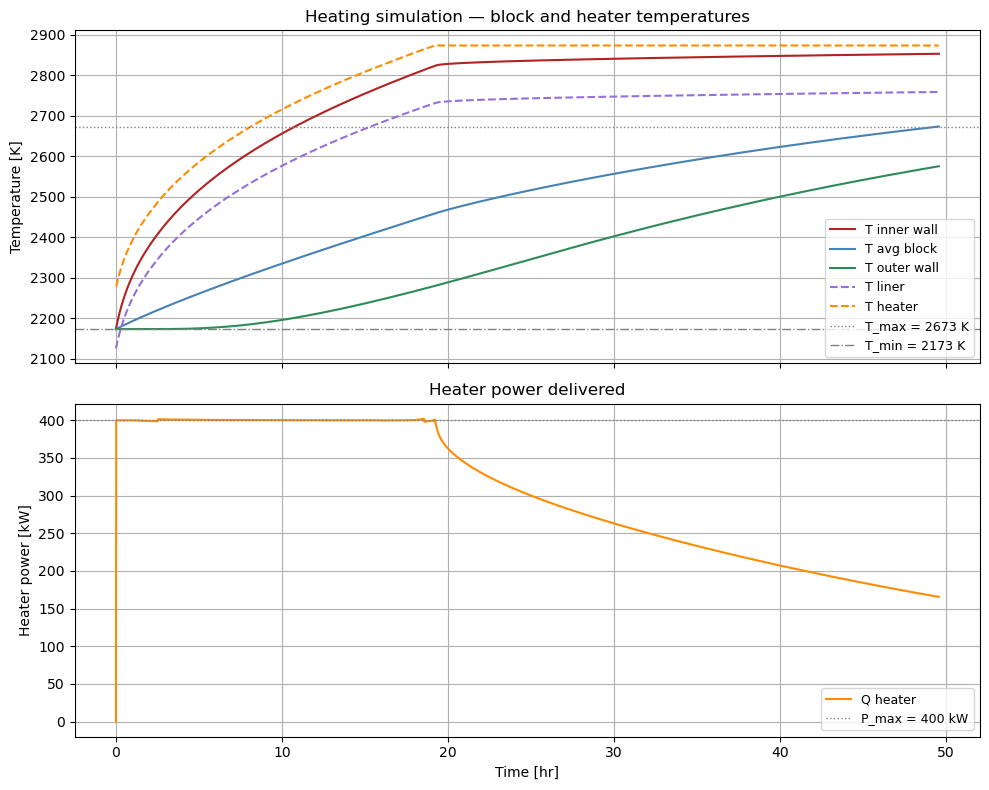

In [ ]:
fig, (ax_T, ax_Q) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

_t_hr = _heat_res['time'] / 3600

# -- Temperature plot ---------------------------------------------------------
ax_T.plot(_t_hr, _heat_res['T_inner'], label='T inner wall', color='firebrick')
ax_T.plot(_t_hr, _heat_res['T_avg'],   label='T avg block',  color='steelblue')
ax_T.plot(_t_hr, _heat_res['T_outer'], label='T outer wall', color='seagreen')
if _heat_res['T_liner'].any():
    ax_T.plot(_t_hr, _heat_res['T_liner'], label='T liner', color='mediumpurple', linestyle='--')
ax_T.plot(_t_hr, _heat_res['T_heater'],label='T heater',     color='darkorange', linestyle='--')
ax_T.axhline(_T_block_max, color='grey', linestyle=':', linewidth=1, label=f'T_max = {_T_block_max} K')
ax_T.axhline(_T_min,       color='grey', linestyle='-.', linewidth=1, label=f'T_min = {_T_min} K')
ax_T.set_ylabel('Temperature [K]')
ax_T.set_title('Heating simulation — block and heater temperatures')
ax_T.legend(fontsize=9)
ax_T.grid(True)

# -- Power plot ---------------------------------------------------------------
ax_Q.plot(_t_hr, _heat_res['Q_heater'] / 1e3, color='darkorange', label='Q heater')
ax_Q.axhline(_he_P_max / 1e3, color='grey', linestyle=':', linewidth=1,
             label=f'P_max = {_he_P_max/1e3:.0f} kW')
ax_Q.set_xlabel('Time [hr]')
ax_Q.set_ylabel('Heater power [kW]')
ax_Q.set_title('Heater power delivered')
ax_Q.legend(fontsize=9)
ax_Q.grid(True)

fig.tight_layout()
plt.show()


In [ ]:
# -- Find heater area_ratio such that block reaches T_block_max at end_time ---
# Objective: T_avg(end_time) - T_block_max = 0.
# Larger area_ratio -> larger r_in_heat -> smaller A_h/A_gr ratio
#   -> smaller enclosure resistance -> more heat -> higher f.
# So: f > 0 (overcharged) -> smaller area_ratio; f < 0 -> larger area_ratio.

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_end_time  = _cfg['end_time']
_dt        = _cfg['dt_short']  # heating uses the short timestep
_sub_steps = _cfg['sub_steps']
_T_sur     = _cfg['T_sur']
_blk_loss  = _cfg['block_heat_loss_bool']
_liner     = _cfg['liner_bool']

_s = _cfg['storage']
_T_min            = _s['T_min']
_block_temp_range = _s['block_temp_range']
_L                = _s['L']
_th_ins           = _s['th_ins']
_num_ax           = _s['num_ax_segments']
_num_rad          = _s['num_rad_segments']
_avg_flux         = _s['avg_flux']
_duration_hr      = _s['duration_hr']

_p = _cfg['powerstick']
_side_len  = _p['side_len']
_T_ps      = _p['cooling_temp']
_f_bare    = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len = _p['liner_side_len']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
               for row in _raw_emis]

_h = _cfg['heater']
_he_side_len = _h['side_len']
_he_T_max    = _h['max_temperature']
_he_P_max    = _h['max_power']
_he_emis     = _h['emissivity']

# -- Derived fixed quantities -------------------------------------------------
_T_block_max   = _T_min + _block_temp_range
_r_heater_eff  = 2 * _he_side_len / np.pi    # effective heater radius (circular equiv)
_he_diam       = 2 * _r_heater_eff            # heater diameter passed to HeatingElement
_A_ps          = 4 * _side_len * _L
_T_avg_mid     = _T_min + _block_temp_range / 2
_e_dens        = storage_rho(_T_avg_mid) * storage_cp(_T_avg_mid) * _block_temp_range
_V_block       = _avg_flux * _A_ps * 1e4 * _duration_hr * 3600 / _e_dens

print(f'V_block = {_V_block:.3f} m^3')
print(f'T_min = {_T_min} K   T_block_max = {_T_block_max} K   end_time = {_end_time/3600:.1f} hr')
print(f'Heater: side_len={_he_side_len} m  D_eff={_he_diam:.4f} m  '
      f'T_max={_he_T_max} K  P_max={_he_P_max/1e3:.0f} kW')
print()

# -- Bisection objective ------------------------------------------------------
def simulate_charge_final_T(area_ratio):
    r_in_      = _r_heater_eff * area_ratio
    r_out_     = np.sqrt(_V_block / (np.pi * _L) + r_in_**2)
    init_dist_ = np.full((_num_ax, _num_rad), float(_T_min))
    block_     = GraphiteBlock(init_dist_, inner_radius=r_in_, outer_radius=r_out_,
                               length=_L, th_ins=_th_ins)
    pipe_      = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    storage_   = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                               num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                               bypass_range=[0, 1])
    ps_        = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                            cooling_temp=_T_ps,
                            f_bare=_f_bare, f_active=_f_active,
                            liner_bool=_liner, liner_width=_liner_side_len,
                            emissivity_table=_emis_table)
    heater_    = HeatingElement(diameter=_he_diam, max_temperature=_he_T_max,
                                max_power=_he_P_max, emissivity=_he_emis)
    sim_       = TinlessSimulation(storage_, ps_, T_sur=_T_sur, block_heat_loss=_blk_loss)
    res_       = sim_.run_heating_simulation(
        heater=heater_, T_block_max=float('inf'),
        end_time=_end_time, dt=_dt, sub_steps=_sub_steps,
    )
    T_final = res_['T_avg'][-1]
    print(f'  area_ratio={area_ratio:6.3f}  r_in={r_in_:.4f} m  '
          f'T_avg_final={T_final:.1f} K  (target {_T_block_max} K)')
    return T_final - _T_block_max

# -- Bisection ----------------------------------------------------------------
_T_tol    = 0.01 * _block_temp_range
_ar_guess = _h['area_ratio']

print('Searching for area_ratio where T_avg(end_time) = T_block_max...')
f0 = simulate_charge_final_T(_ar_guess)

if abs(f0) <= _T_tol:
    ar_opt = _ar_guess
else:
    if f0 > 0:          # overcharged -> need smaller area_ratio
        ar_hi, f_hi = _ar_guess, f0
        ar_lo = _ar_guess
        while True:
            ar_lo /= 2
            f_lo = simulate_charge_final_T(ar_lo)
            if f_lo <= 0:
                break
            ar_hi, f_hi = ar_lo, f_lo
    else:               # undercharged -> need larger area_ratio
        ar_lo, f_lo = _ar_guess, f0
        ar_hi = _ar_guess
        while True:
            ar_hi *= 2
            f_hi = simulate_charge_final_T(ar_hi)
            if f_hi >= 0:
                break
            ar_lo, f_lo = ar_hi, f_hi

    print(f'Bracket: [{ar_lo:.3f}, {ar_hi:.3f}]')

    for _ in range(20):
        ar_mid = (ar_lo + ar_hi) / 2
        f_mid  = simulate_charge_final_T(ar_mid)
        if abs(f_mid) <= _T_tol:
            break
        if f_mid > 0:
            ar_hi = ar_mid
        else:
            ar_lo = ar_mid

    ar_opt = (ar_lo + ar_hi) / 2

_r_in_opt  = _r_heater_eff * ar_opt
_r_out_opt = np.sqrt(_V_block / (np.pi * _L) + _r_in_opt**2)
print()
print(f'Optimal heater area_ratio = {ar_opt:.3f}')
print(f'  r_in  = {_r_in_opt:.4f} m   D_in  = {2*_r_in_opt:.4f} m')
print(f'  r_out = {_r_out_opt:.4f} m   D_out = {2*_r_out_opt:.4f} m')
print(f'  D_in / D_heater = {2*_r_in_opt / _he_diam:.3f}')


V_block = 39.351 m^3
T_min = 2173 K   T_block_max = 2673 K   end_time = 50.0 hr
Heater: side_len=0.15 m  D_eff=0.1910 m  T_max=2873 K  P_max=400 kW

Searching for area_ratio where T_avg(end_time) = T_block_max...


C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\642108264.py:201: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
C:\Users\NateColgan\AppData\Local\Temp\ipykernel_104212\642108264.py:209: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


  area_ratio=10.000  r_in=0.9549 m  T_avg_final=2694.5 K  (target 2673 K)
  area_ratio= 5.000  r_in=0.4775 m  T_avg_final=2596.7 K  (target 2673 K)
Bracket: [5.000, 10.000]
  area_ratio= 7.500  r_in=0.7162 m  T_avg_final=2652.2 K  (target 2673 K)
  area_ratio= 8.750  r_in=0.8356 m  T_avg_final=2675.0 K  (target 2673 K)

Optimal heater area_ratio = 8.750
  r_in  = 0.8356 m   D_in  = 1.6711 m
  r_out = 2.1926 m   D_out = 4.3853 m
  D_in / D_heater = 8.750


In [ ]:
import thermal.components as _tc
from scipy.integrate import cumulative_trapezoid

# ── Fixed design parameters ──────────────────────────────────────────────
_avg_flux        = 10          # W/cm^2
_duration_hr     = 50          # hr  (fixed discharge duration)
_side_len        = 0.13        # m
_L               = 3.0         # m
_th_ins          = 0.0         # m
_num_ax          = 2
_num_rad         = 10
_T_ps            = 323         # K
_f_bare          = 0
_f_active        = 0.83
_T_sur            = 300         # K
_dt              = 1200        # s
_sub_steps       = 5
_pwr_tol         = 0.01        # bisection tolerance (fraction of avg_power)
_T_max           = 2173        # K  (block full/maximum temperature)
_liner_side_len  = 0.20        # m  (square side length of tungsten liner)

_r_ps_eff      = 2 * _side_len / np.pi
_avg_power = _avg_flux * 1e4 * 4 * _side_len * _L * (1.0 - _f_bare) * _f_active  # cell-weighted [W]

# ── Sweep parameters ─────────────────────────────────────────────────────
liner_bool_vals = [False, True]           # tungsten liner on/off
#liner_bool_vals = [True]           # tungsten liner on/off
temp_range_vals = [250, 375, 500]         # K  (block operating temperature swing)
#temp_range_vals = [300]         # K  (block operating temperature swing)
bandgap_vals    = [1.24, 1.38, 1.55]     # microns
#bandgap_vals    = [1.55]     # microns

# ── Helpers ───────────────────────────────────────────────────────────────
def _build_and_run(T_max, dT_range, area_ratio, emis_table, liner_bool_):
    """
    Size a graphite storage block and run a full transient discharge simulation.

    T_min = T_max - dT_range.
    Block volume is sized from the required energy; inner radius follows from
    area_ratio = r_in / r_ps_eff; outer radius derived from V_block and r_in.
    """
    T_min     = T_max - dT_range
    T_avg_mid = T_min + dT_range / 2
    e_dens_   = storage_rho(T_avg_mid) * storage_cp(T_avg_mid) * dT_range
    f_cell_      = (1.0 - _f_bare) * _f_active
    f_inact_     = (1.0 - _f_bare) * (1.0 - _f_active)
    ps_tmp_      = PowerStick(axial_steps=1, width=_side_len, height=_L,
                             cooling_temp=_T_ps,
                             f_bare=_f_bare, f_active=_f_active,
                             liner_bool=liner_bool_, liner_width=_liner_side_len,
                             emissivity_table=emis_table)
    inc_bins_, _, _ = ps_tmp_.incident_energy(T_min, 1.0)
    inc_tot_     = sum(inc_bins_.values())
    f_Q_         = sum(
        inc_bins_[row[0]] / inc_tot_ * f_cell_ * row[1]
        / (_f_bare * row[2] + f_cell_ * row[1] + f_inact_ * row[3])
        for row in emis_table)
    tot_power_   = _avg_flux * 1e4 * 4 * _side_len * _L * f_cell_ / f_Q_
    V_blk_    = tot_power_ * _duration_hr * 3600 / e_dens_
    r_in_     = _r_ps_eff * area_ratio
    r_out_    = np.sqrt(V_blk_ / (np.pi * _L) + r_in_**2)

    init_dist_ = np.full((_num_ax, _num_rad), float(T_max))
    block_  = GraphiteBlock(init_dist_, inner_radius=r_in_, outer_radius=r_out_,
                            length=_L, th_ins=_th_ins)
    pipe_   = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    stor_   = StorageModule(N_pipes=1, Pipe=pipe_, Block=block_,
                            num_ax_segments=_num_ax, num_rad_segments=_num_rad,
                            bypass_range=[0, 1])
    ps_     = PowerStick(axial_steps=_num_ax, width=_side_len, height=_L,
                         cooling_temp=_T_ps,
                         f_bare=_f_bare, f_active=_f_active,
                         liner_bool=liner_bool_, liner_width=_liner_side_len,
                         emissivity_table=emis_table)
    sim_    = TinlessSimulation(stor_, ps_, T_sur=_T_sur, block_heat_loss=False)
    res_    = sim_.run_simulation(end_time=_duration_hr * 3600, dt=_dt, sub_steps=_sub_steps)
    return res_, r_out_

def _pss_avg_q(res_, dT_range, T_max):
    """
    Compute average cell heat flux over the pseudo-steady-state window.
    PSS onset fixed at t=0; window ends when SOC drops to zero.
    """
    T_min    = T_max - dT_range
    soc      = (res_['T_avg'] - T_min) / dT_range
    idx_pss  = int(0)
    soc0     = np.where(soc <= 0)[0]
    idx_soc0 = int(soc0[0]) if len(soc0) else len(soc) - 1
    if idx_pss >= idx_soc0:
        return float(res_['Q_cell'][idx_pss])
    return float(res_['Q_cell'][idx_pss:idx_soc0 + 1].mean())

# ── Main sweep ───────────────────────────────────────────────────────────
sweep_results = {}
total = len(liner_bool_vals) * len(bandgap_vals) * len(temp_range_vals)
n = 0

for liner_bool_ in liner_bool_vals:
    for bg_val in bandgap_vals:
        emis_table_bg = [
            ((0.1,    bg_val), 0.9,  0.1, 0.1),
            ((bg_val, 20.0),   0.05, 0.1, 0.1),
        ]
        for dT_range in temp_range_vals:
            n += 1
            print(f'[{n}/{total}] liner={liner_bool_}  dT={dT_range}K  T_min={_T_max - dT_range}K  bg={bg_val}um  -- bisecting area_ratio')

            try:
                def _f(ar, _Tmax=_T_max, _dT=dT_range, _emis=emis_table_bg, _lb=liner_bool_):
                    res_, _ = _build_and_run(_Tmax, _dT, ar, _emis, _lb)
                    q = _pss_avg_q(res_, _dT, _Tmax)
                    print(f'    ar={ar:.3f}  avg_Q={q/1e3:.1f} kW  (target {_avg_power/1e3:.0f} kW)')
                    return q - _avg_power

                f0 = _f(10.0)
                if abs(f0) / _avg_power <= _pwr_tol:
                    ar_opt = 10.0
                else:
                    if f0 > 0:
                        ar_hi, f_hi = 10.0, f0
                        ar_lo = 10.0
                        while True:
                            ar_lo /= 2
                            f_lo = _f(ar_lo)
                            if f_lo <= 0:
                                break
                            ar_hi, f_hi = ar_lo, f_lo
                    else:
                        ar_lo, f_lo = 10.0, f0
                        ar_hi = 10.0
                        while True:
                            ar_hi *= 2
                            f_hi = _f(ar_hi)
                            if f_hi >= 0:
                                break
                            ar_lo, f_lo = ar_hi, f_hi

                    for _ in range(20):
                        ar_mid = (ar_lo + ar_hi) / 2
                        f_mid  = _f(ar_mid)
                        if abs(f_mid) / _avg_power <= _pwr_tol:
                            break
                        if f_mid > 0:
                            ar_hi = ar_mid
                        else:
                            ar_lo = ar_mid
                    ar_opt = (ar_lo + ar_hi) / 2

                res_opt, r_out_opt = _build_and_run(_T_max, dT_range, ar_opt, emis_table_bg, liner_bool_)
                Q  = res_opt['Q_rad']
                Q_cell = res_opt['Q_cell']
                Pe = res_opt['P_elec']
                Ti = res_opt['T_inner']
                Ta = res_opt['T_avg']
                t  = res_opt['time']
                cum_Q = cumulative_trapezoid(Q,  t, initial=0)
                cum_Q_cell = cumulative_trapezoid(Q_cell, t, initial=0)
                cum_P = cumulative_trapezoid(Pe, t, initial=0)
                eff   = cum_P[-1] / cum_Q[-1] * 100 if cum_Q[-1] > 0 else 0.0
                eff_cell = cum_P[-1] / cum_Q_cell[-1] * 100 if cum_Q_cell[-1] > 0 else 0.0

                sweep_results[(dT_range, bg_val, liner_bool_)] = dict(
                    area_ratio = ar_opt,
                    r_out      = r_out_opt,
                    peak_dT    = float(np.max(Ta - Ti)),
                    peak_power = float(np.max(Q)) / 1e3,
                    min_power  = float(np.min(Q)) / 1e3,
                    efficiency = eff,
                    efficiency_cell = eff_cell,
                    avg_cell_flux  = float(Q_cell.mean()) / (4 * _side_len * _L * (1.0 - _f_bare) * _f_active * 1e4),
                )
                print(f'    -> ar_opt={ar_opt:.3f}  r_out={r_out_opt:.3f}m  '
                      f'peak_Q={np.max(Q)/1e3:.0f}kW  eff={eff:.1f}%')
            except Exception as e:
                print(f'    ERROR ({type(e).__name__}): {e} — skipping')

print('Sweep complete.')


[1/18] liner=False  dT=250K  T_min=1923K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[2/18] liner=False  dT=375K  T_min=1798K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[3/18] liner=False  dT=500K  T_min=1673K  bg=1.24um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[4/18] liner=False  dT=250K  T_min=1923K  bg=1.38um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[5/18] liner=False  dT=375K  T_min=1798K  bg=1.38um  -- bisecting area_ratio
    ERROR (TypeError): TinlessSimulation.run_simulation() got an unexpected keyword argument 'dt' — skipping
[6/18] liner=False  dT=500K  T_min=1673K  bg=1.38um  -- bisecting area

In [ ]:
dT_colors    = plt.cm.plasma(np.linspace(0.15, 0.85, len(temp_range_vals)))
liner_styles = {False: '-', True: '--'}
liner_labels = {False: 'no liner', True: 'W liner'}

fig, axes = plt.subplots(4, 2, figsize=(12, 18))

ax_ar,  ax_rout    = axes[0]
ax_eff,  ax_pwr     = axes[1]
ax_eff_c, ax_min_pwr = axes[2]
ax_bl2, ax_bl3     = axes[3]

for ci, dT_range in enumerate(temp_range_vals):
    for liner_bool_ in liner_bool_vals:
        try:
            lbl    = f'ΔT={dT_range}K, {liner_labels[liner_bool_]}'
            kwargs = dict(color=dT_colors[ci], linestyle=liner_styles[liner_bool_],
                          marker='o', label=lbl)

            ax_ar.plot(      bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['area_ratio'] for bg in bandgap_vals], **kwargs)
            ax_rout.plot(    bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['r_out']      for bg in bandgap_vals], **kwargs)
            #ax_dT.plot(      bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['peak_dT']    for bg in bandgap_vals], **kwargs)
            ax_pwr.plot(     bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['peak_power'] / (4 * _side_len * _L * (1 - _f_bare) * _f_active * 10) for bg in bandgap_vals], **kwargs)
            ax_min_pwr.plot( bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['min_power']  / (4 * _side_len * _L * (1 - _f_bare) * _f_active * 10) for bg in bandgap_vals], **kwargs)
            ax_eff.plot(   bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['efficiency'] for bg in bandgap_vals], **kwargs)
            ax_eff_c.plot(   bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['efficiency_cell'] for bg in bandgap_vals], **kwargs)
            ax_bl2.plot(     bandgap_vals, [sweep_results[(dT_range, bg, liner_bool_)]['avg_cell_flux']    for bg in bandgap_vals], **kwargs)
        except KeyError:
            pass

ax_ar.set_ylabel('Optimal area ratio')
ax_ar.set_title('Optimal area ratio')
ax_rout.set_ylabel('Outer radius [m]')
ax_rout.set_title('Block outer radius')
#ax_dT.set_ylabel('Peak ΔT (inner − avg) [K]')
#ax_dT.set_title('Peak inner wall dT')
ax_pwr.set_ylabel('Peak power density [W/cm²]')
ax_pwr.set_title('Peak power (start of discharge)')
ax_min_pwr.set_ylabel('Min power density [W/cm²]')
ax_min_pwr.set_title('Min power (end of discharge)')
ax_eff.set_ylabel('Overall efficiency [%]')
ax_eff.set_title('Cumulative elec / thermal')
ax_eff_c.set_ylabel('Cell efficiency [%]')
ax_eff_c.set_title('Cumulative elec / cell thermal')
ax_bl2.set_ylabel('Avg cell flux [W/cm²]')
ax_bl2.set_title('Average cell power density')

for ax in [ax_ar, ax_rout, ax_pwr, ax_min_pwr, ax_eff, ax_eff_c, ax_bl2]:
    ax.set_xlabel('Bandgap [μm]')
    ax.grid(True)

for ax in [ax_bl3]:
    ax.set_visible(False)

ax_ar.legend(fontsize=9)
fig.suptitle(
    f'Parametric sweep  |  f_bare={_f_bare}  T_max={_T_max} K  dur={_duration_hr} hr  avg_flux={_avg_flux} W/cm²',
    fontsize=10,
)
fig.tight_layout()
plt.show()


r_ps_eff  = 8.28 cm
r_liner   = 19.10 cm
r_shield  = 20.37 cm
r_in      = 50.00 cm
A_cell    = 15600.0 cm²


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:219: RuntimeWarning: divide by zero encountered in divide
  B_lin     = _B(T_liner)
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:227: RuntimeWarning: divide by zero encountered in divide
  n_ax       = self.storage.num_ax_segments


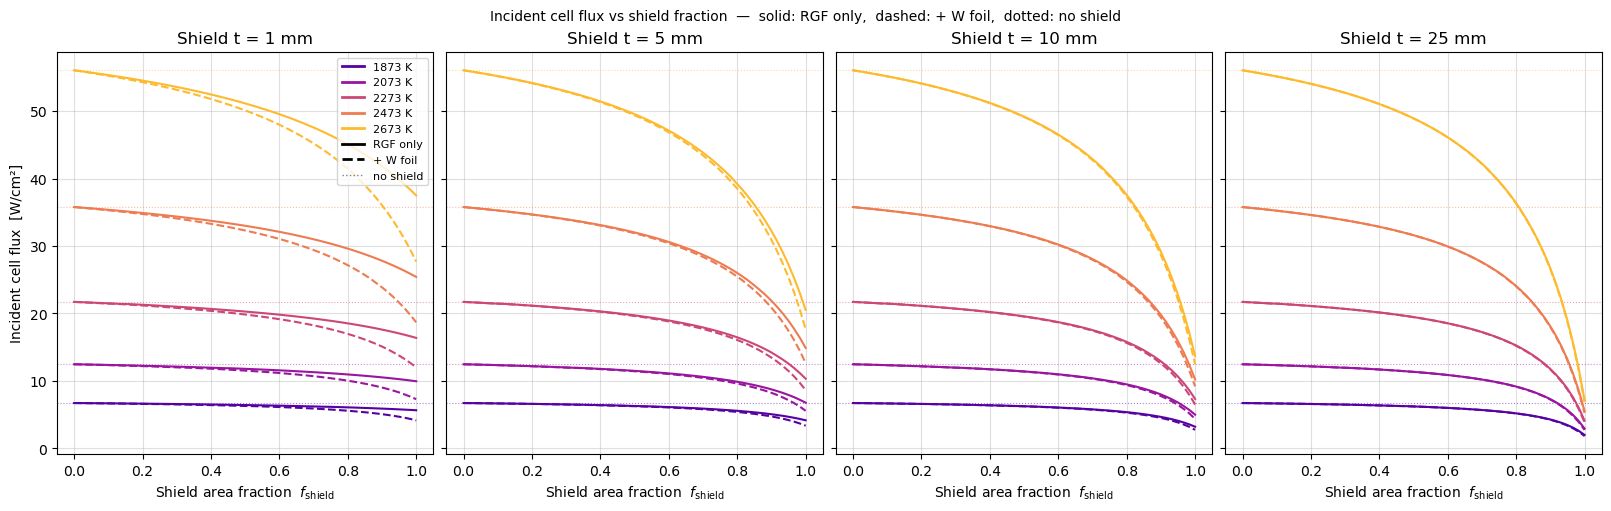


Cell flux [W/cm²] at f_shield = 0.5
     T_hot  no shield      t=1mm      t=5mm     t=10mm     t=25mm    t=1mm+W    t=5mm+W   t=10mm+W   t=25mm+W
      1873       6.73       6.44       6.30       6.26       6.24       6.30       6.27       6.26       6.24
      2073      12.47      11.81      11.52      11.44      11.38      11.56      11.47      11.42      11.38
      2273      21.72      20.32      19.78      19.63      19.53      19.90      19.69      19.61      19.53
      2473      35.78      33.07      32.11      31.88      31.72      32.39      32.00      31.84      31.71
      2673      56.05      51.26      49.72      49.37      49.13      50.26      49.57      49.32      49.12


In [ ]:
# -- Scratch: shade sensitivity -- incident cell flux vs f_shade -----------------
# Sweeps shade area fraction for different shade thicknesses.
# Compares RGF-only shade (solid) vs shade with W foil on outer face (dashed).
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# -- Inputs -------------------------------------------------------------------
side_len        = 0.13    # powerstick square side [m]
liner_side_len  = 0.30    # liner square side [m]
shade_side_len = 0.32    # shade square side [m]
r_in            = 0.50    # graphite inner-wall effective radius [m]
L               = 3.0     # axial length [m]
f_bare          = 0.0
f_active        = 1.0

band_gap = 1.24
emissivity_table = [
    ((0.1,      band_gap), 0.9,  0.10, 0.10),
    ((band_gap, 20.0    ), 0.05, 0.10, 0.10),
]

T_hot_vals     = [1873, 2073, 2273, 2473, 2673]  # graphite inner-wall temperatures [K]
thickness_vals = [0.001, 0.005, 0.010, 0.025]    # insulation thickness to sweep [m]
eps_sh         = 0.9
f_shade_arr   = np.linspace(0, 1, 60)

# -- Derived geometry ---------------------------------------------------------
r_ps_eff = 2 * side_len / np.pi
r_liner  = 2 * liner_side_len / np.pi
r_shade = 2 * shade_side_len / np.pi

VF_gr_liner   = r_liner  / r_in
VF_liner_ps   = r_ps_eff / r_liner
VF_gr_shade  = r_shade / r_in
VF_shade_lin = r_liner  / r_shade

height_step  = L
A_ps_seg     = 4 * side_len * L
A_liner_seg  = 2 * np.pi * r_liner  * height_step
A_shade_seg = 2 * np.pi * r_shade * height_step
A_gr_seg     = 2 * np.pi * r_in     * height_step
A_cell_cm2   = A_ps_seg * (1 - f_bare) * f_active * 1e4

print(f"r_ps_eff  = {r_ps_eff*100:.2f} cm")
print(f"r_liner   = {r_liner*100:.2f} cm")
print(f"r_shade  = {r_shade*100:.2f} cm")
print(f"r_in      = {r_in*100:.2f} cm")
print(f"A_cell    = {A_cell_cm2:.1f} cm\u00b2")

# -- Mock sim object ----------------------------------------------------------
class _M:
    pass

def _make_sim(thickness, foil=False):
    m = _M()
    m.powerstick                      = _M()
    m.powerstick.emissivity_table     = emissivity_table
    m.powerstick.liner_bool           = True
    m.powerstick.f_bare               = f_bare
    m.powerstick.f_active             = f_active
    m.VF                              = VF_gr_liner
    m.A_ps_seg                        = A_ps_seg
    m.shade_bool                     = True
    m.shade_thickness                = thickness
    m.shade_surface_emissivity = eps_sh
    m.shade_outer_foil         = foil
    m.liner_material            = 'tac'
    m.shade_num_conduction_layers    = 5
    m.VF_gr_liner                     = VF_gr_liner
    m.VF_liner_ps                     = VF_liner_ps
    m.A_liner_seg                     = A_liner_seg
    m.VF_gr_shade                    = VF_gr_shade
    m.VF_shade_lin                   = VF_shade_lin
    m.A_shade_seg                    = A_shade_seg
    m.A_gr_seg                        = A_gr_seg
    return m

# No-shade baseline (foil irrelevant)
sim_noshade = _make_sim(0.05)
sim_noshade.shade_bool = False

flux_noshade = {}
for T_hot in T_hot_vals:
    Q_ps, _, _ = TinlessSimulation.spectral_net_radiation(sim_noshade, T_hot, f_shade=0.0)
    flux_noshade[T_hot] = Q_ps / A_cell_cm2

# -- Sweep: (thickness, T_hot, foil) -> flux array over f_shade --------------
flux = {}
for thk in thickness_vals:
    for foil in [False, True]:
        sim = _make_sim(thk, foil=foil)
        for T_hot in T_hot_vals:
            vals = [
                TinlessSimulation.spectral_net_radiation(sim, T_hot, f_shade=fs)[0] / A_cell_cm2
                for fs in f_shade_arr
            ]
            flux[(thk, T_hot, foil)] = np.array(vals)

# -- Plot: one subplot per thickness ------------------------------------------
colors      = plt.cm.plasma(np.linspace(0.15, 0.85, len(T_hot_vals)))
foil_styles = {False: '-', True: '--'}

fig, axes = plt.subplots(1, len(thickness_vals), figsize=(16, 5), sharey=True,
                         constrained_layout=True)

for ax, thk in zip(axes, thickness_vals):
    for color, T_hot in zip(colors, T_hot_vals):
        for foil in [False, True]:
            ax.plot(f_shade_arr, flux[(thk, T_hot, foil)],
                    color=color, ls=foil_styles[foil], lw=1.5)
        ax.axhline(flux_noshade[T_hot], color=color, ls=':', lw=0.8, alpha=0.5)
    ax.set_title(f'Shade t = {thk*1000:.0f} mm')
    ax.set_xlabel('Shade area fraction  $f_{{\\mathrm{{shade}}}}$')
    ax.grid(True, alpha=0.4)

axes[0].set_ylabel('Incident cell flux  [W/cm\u00b2]')

# Legend: colors = T_hot, linestyle = foil variant
lh, ll = [], []
for color, T_hot in zip(colors, T_hot_vals):
    lh.append(Line2D([0],[0], color=color, lw=2))
    ll.append(f'{T_hot} K')
lh.append(Line2D([0],[0], color='k', ls='-',  lw=2));          ll.append('RGF only')
lh.append(Line2D([0],[0], color='k', ls='--', lw=2));          ll.append('+ W foil')
lh.append(Line2D([0],[0], color='k', ls=':',  lw=1, alpha=0.5)); ll.append('no shade')
axes[0].legend(lh, ll, fontsize=8, loc='upper right')

fig.suptitle(
    'Incident cell flux vs shade fraction  \u2014  solid: RGF only,  dashed: + W foil,  dotted: no shade',
    fontsize=10,
)
plt.show()

# -- Summary table at f_shade = 0.5 ------------------------------------------
fs_ref = 0.5
i_ref  = np.argmin(np.abs(f_shade_arr - fs_ref))
print(f"\nCell flux [W/cm\u00b2] at f_shade = {fs_ref}")
col_rgf = [f"t={thk*1000:.0f}mm" for thk in thickness_vals]
col_w   = [f"t={thk*1000:.0f}mm+W" for thk in thickness_vals]
header  = "  ".join(f"{h:>9}" for h in col_rgf + col_w)
print(f"{'T_hot':>10}  {'no shade':>9}  {header}")
for T_hot in T_hot_vals:
    rgf = "  ".join(f'{flux[(thk, T_hot, False)][i_ref]:>9.2f}' for thk in thickness_vals)
    wf  = "  ".join(f'{flux[(thk, T_hot, True )][i_ref]:>9.2f}' for thk in thickness_vals)
    print(f"{T_hot:>10}  {flux_noshade[T_hot]:>9.2f}  {rgf}  {wf}")


Saved efficiency_vs_temperature.csv


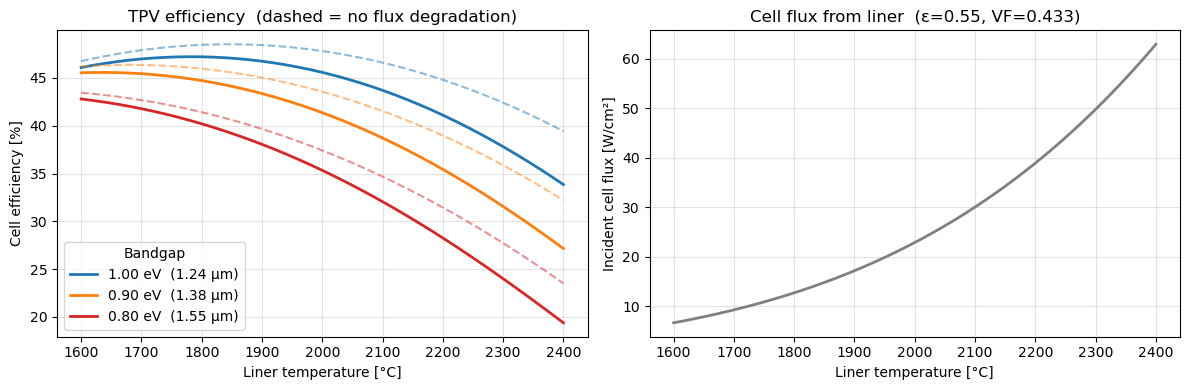

In [ ]:
# -- Cell efficiency vs emitter temperature — with flux degradation -----------
# Flux calculated via PowerStick.incident_energy() so powerstick emissivity
# table and view factor are applied correctly (not a blackbody assumption).
import csv, yaml, numpy as np, matplotlib.pyplot as plt
from thermal.properties import panel_efficiency

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_p              = _cfg['powerstick']
_s              = _cfg['storage']
_side_len       = _p['side_len']
_area_ratio     = _p['area_ratio']
_f_bare         = _p['f_bare']
_f_active       = _p['f_active']
_liner_side_len = _p['liner_side_len']
_L              = _s['L']
_num_ax         = _s['num_ax_segments']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in _raw_emis]

_r_ps_eff    = 2 * _side_len / np.pi
_r_in        = _r_ps_eff * _area_ratio
_r_liner     = 2 * _liner_side_len / np.pi
_VF_liner_ps = _r_ps_eff / _r_liner

# Build a single-step PowerStick (1 axial segment = full length)
_ps = PowerStick(axial_steps=1, width=_side_len, height=_L,
                 cooling_temp=300, f_bare=_f_bare, f_active=_f_active,
                 liner_bool=True, liner_width=_liner_side_len,
                 emissivity_table=_emis_table)

bandgaps = [1.24, 1.38, 1.55]
bg_eV    = [1.2398 / bg for bg in bandgaps]
T_C      = np.linspace(1600, 2400, 200)
T_K      = T_C + 273.15

# Compute flux_wcm2 at each temperature using incident_energy — same formula
# as generate_electricity_step so powerstick emissivity is properly applied.
def _flux_wcm2(T):
    inc_bins, _, _ = _ps.incident_energy(T, _VF_liner_ps)
    absorbed_cell = 0.0
    for i, (wr, ea, eb, ei) in enumerate(_emis_table):
        avg = _f_bare*eb + (1-_f_bare)*_f_active*ea + (1-_f_bare)*(1-_f_active)*ei
        if avg > 0:
            absorbed_cell += inc_bins[wr] * (1-_f_bare) * _f_active * ea / avg
    cell_flux_W = absorbed_cell * _ps.A_step
    return cell_flux_W / (_ps.A_step * (1-_f_bare) * _f_active * 1e4)

flux_wcm2 = np.array([_flux_wcm2(T) for T in T_K])

# Pre-compute efficiency arrays — reused for CSV and plot
eff_base_all = {bg: np.array([panel_efficiency(bg, T) * 100 for T in T_K])
                for bg in bandgaps}
eff_flux_all = {bg: np.array([panel_efficiency(bg, T, flux=f) * 100
                               for T, f in zip(T_K, flux_wcm2)])
                for bg in bandgaps}

# -- Export to CSV -----------------------------------------------------------
_csv_path = 'efficiency_vs_temperature.csv'
_headers  = (['T_C', 'flux_wcm2']
             + [f'eff_no_flux_{bg}um_pct'   for bg in bandgaps]
             + [f'eff_with_flux_{bg}um_pct' for bg in bandgaps])
with open(_csv_path, 'w', newline='') as _cf:
    _w = csv.writer(_cf)
    _w.writerow(_headers)
    for j in range(len(T_C)):
        _w.writerow(
            [round(T_C[j], 4), round(flux_wcm2[j], 6)]
            + [round(eff_base_all[bg][j], 6) for bg in bandgaps]
            + [round(eff_flux_all[bg][j], 6) for bg in bandgaps]
        )
print(f'Saved {_csv_path}')

# -- Plot --------------------------------------------------------------------
colors = ['C0', 'C1', 'C3']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
for bg, eV, col in zip(bandgaps, bg_eV, colors):
    ax.plot(T_C, eff_base_all[bg], color=col, lw=1.5, ls='--', alpha=0.5)
    ax.plot(T_C, eff_flux_all[bg], color=col, lw=2, label=f'{eV:.2f} eV  ({bg} μm)')

ax.set_xlabel('Liner temperature [°C]')
ax.set_ylabel('Cell efficiency [%]')
ax.set_title('TPV efficiency  (dashed = no flux degradation)')
ax.legend(title='Bandgap')
ax.grid(True, alpha=0.35)

ax2 = axes[1]
ax2.plot(T_C, flux_wcm2, color='gray', lw=2)
ax2.set_xlabel('Liner temperature [°C]')
ax2.set_ylabel('Incident cell flux [W/cm²]')
ax2.set_title(f'Cell flux from liner  (ε=0.55, VF={_VF_liner_ps:.3f})')
ax2.grid(True, alpha=0.35)

fig.tight_layout()
plt.show()


Shield perimeter : 2.8970 m
f_shield_max     : 0.9912  (fully closed, 3.17 mm corner gaps)
f_shield_min     : 0.0276  (fully open,   10.0 mm panel thickness)


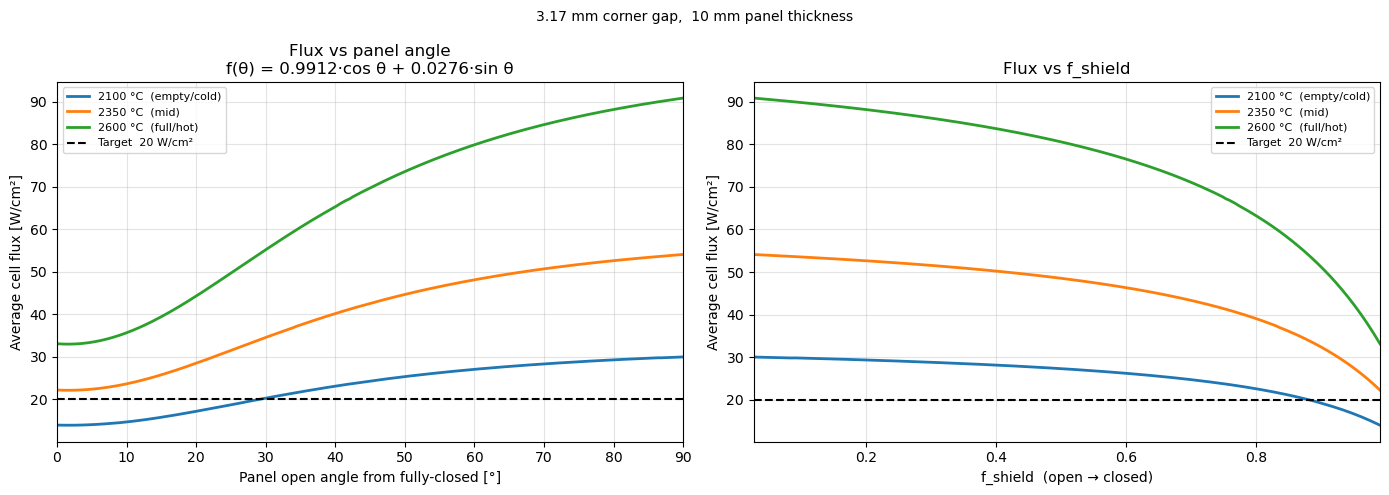

In [ ]:
# -- Shade panel open angle vs average cell flux ------------------------------
# The octagonal shade has 8 flat panels that pivot on their centre (axial)
# axis.  At angle θ from the fully-closed position each panel projects:
#
#   width_projected = W_panel * cos(θ) + thickness * sin(θ)
#
# Summing over all 8 panels and dividing by shade perimeter P:
#
#   f_shade(θ) = f_shade_max * cos(θ) + f_shade_min * sin(θ)
#
# Physical boundary conditions (not bisection bounds):
#   f_shade_max = (P - 8*g) / P   θ = 0°  (fully closed, corner gaps pass light)
#   f_shade_min =   8*t    / P    θ = 90° (fully open, only panel edge visible)
#
# g = corner_gap, t = shade thickness, P = shade perimeter = ratio * 4 * liner_side_len

import types, yaml, numpy as np, matplotlib.pyplot as plt
from thermal import PowerStick, TinlessSimulation

with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_p  = _cfg['powerstick']
_s  = _cfg['storage']
_sh = _cfg.get('shade', {})

side_len       = _p['side_len']
area_ratio     = _p['area_ratio']
f_bare         = _p['f_bare']
f_active       = _p['f_active']
cooling_temp   = _p['cooling_temp']
liner_side_len = _p['liner_side_len']
L              = _s['L']
num_ax         = _s['num_ax_segments']
num_rad        = _s['num_rad_segments']
T_min          = _s['T_min']
T_swing        = _s['block_temp_range']
avg_flux       = _s['avg_flux']

liner_bool     = _cfg.get('liner_bool', True)
liner_material = _cfg.get('liner_material', 'tac')
shade_bool    = _sh.get('shade_bool', _cfg.get('shade_bool', False))
ratio          = _sh.get('liner_to_shade_perimeter_ratio', None)
shade_side_len = ratio * liner_side_len if ratio else None
shade_thick   = _sh.get('thickness', 0.01)
shade_emis       = _sh.get('surface_emissivity', 0.9)
shade_outer_foil = _sh.get('outer_foil', False)
shade_layers  = _sh.get('num_conduction_layers', 5)
corner_gap     = _sh.get('corner_gap', 0.003175)

shade_perimeter = ratio * 4 * liner_side_len if ratio else None
f_shade_max = 1 - 8 * corner_gap  / shade_perimeter  if shade_perimeter else 0.99
f_shade_min = 8 * shade_thick    / shade_perimeter   if shade_perimeter else 0.03

print(f'Shade perimeter : {shade_perimeter:.4f} m')
print(f'f_shade_max     : {f_shade_max:.4f}  (fully closed, {corner_gap*1e3:.2f} mm corner gaps)')
print(f'f_shade_min     : {f_shade_min:.4f}  (fully open,   {shade_thick*1e3:.1f} mm panel thickness)')

raw_emis   = _cfg['emissivity_tables'][0]['value']
emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in raw_emis]

r_ps_eff = 2 * side_len / np.pi
r_in     = r_ps_eff * area_ratio

_storage = types.SimpleNamespace(
    block=types.SimpleNamespace(rad_in=r_in),
    num_ax_segments=num_ax,
)

ps = PowerStick(axial_steps=num_ax, width=side_len, height=L,
                cooling_temp=cooling_temp, f_bare=f_bare, f_active=f_active,
                liner_bool=liner_bool, liner_width=liner_side_len,
                emissivity_table=emis_table)

sim = TinlessSimulation(
    _storage, ps,
    T_sur=_cfg.get('T_sur', 300),
    block_heat_loss=_cfg.get('block_heat_loss_bool', False),
    shade_bool=shade_bool, shade_side_len=shade_side_len,
    shade_thickness=shade_thick,
    shade_surface_emissivity=shade_emis,
    shade_outer_foil=shade_outer_foil,
    shade_num_conduction_layers=shade_layers,
    f_shade_min=f_shade_min, f_shade_max=f_shade_max,
    nominal_cell_flux=avg_flux,
    liner_material=liner_material,
)

N         = 200

# Angle sweep: θ = 0° (fully closed) → 90° (fully open)
theta_deg    = np.linspace(0, 90, N)
theta_rad    = np.radians(theta_deg)
f_from_angle = f_shade_max * np.cos(theta_rad) + f_shade_min * np.sin(theta_rad)

# Direct f_shade sweep: linear from fully-open to fully-closed
f_direct = np.linspace(f_shade_min, f_shade_max, N)

A_cell_cm2 = ps.A_step * (1 - f_bare) * f_active * 1e4

T_walls   = [T_min, T_min + T_swing / 2, T_min + T_swing]
_suffixes = ['(empty/cold)', '(mid)', '(full/hot)']
T_labels  = [f'{_T - 273.15:.0f} \u00b0C  {_sfx}' for _T, _sfx in zip(T_walls, _suffixes)]

import warnings
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    for T_wall, label in zip(T_walls, T_labels):
        flux_angle = np.array([
            sim.spectral_net_radiation(T_wall, f_shade=f)[2] / A_cell_cm2
            for f in f_from_angle
        ])
        flux_fshade = np.array([
            sim.spectral_net_radiation(T_wall, f_shade=f)[2] / A_cell_cm2
            for f in f_direct
        ])
        ax1.plot(theta_deg, flux_angle,   lw=2, label=label)
        ax2.plot(f_direct,  flux_fshade, lw=2, label=label)

# Left: angle
ax1.axhline(avg_flux, ls='--', color='k', lw=1.5, label=f'Target  {avg_flux} W/cm\u00b2')
ax1.set_xlabel('Panel open angle from fully-closed [\u00b0]')
ax1.set_ylabel('Average cell flux [W/cm\u00b2]')
ax1.set_title(
    'Flux vs panel angle\n'
    f'f(\u03b8) = {f_shade_max:.4f}\u00b7cos \u03b8 + {f_shade_min:.4f}\u00b7sin \u03b8'
)
ax1.legend(fontsize=8)
ax1.set_xlim(0, 90)
ax1.grid(True, alpha=0.35)

# Right: f_shade
ax2.axhline(avg_flux, ls='--', color='k', lw=1.5, label=f'Target  {avg_flux} W/cm\u00b2')
ax2.set_xlabel('f_shade  (open \u2192 closed)')
ax2.set_ylabel('Average cell flux [W/cm\u00b2]')
ax2.set_title('Flux vs f_shade')
ax2.legend(fontsize=8)
ax2.set_xlim(f_shade_min, f_shade_max)
ax2.grid(True, alpha=0.35)

fig.suptitle(
    f'{corner_gap*1e3:.2f} mm corner gap,  {shade_thick*1e3:.0f} mm panel thickness',
    fontsize=10,
)
plt.tight_layout()
plt.show()


In [ ]:
# -- Scratch: parametric sweep  thickness x T_max x T_range x W-foil ---------
# Self-contained: reads config from YAML, rebuilds geometry for each case.
# thickness=0 -> shade_bool=False (no shade baseline); >0 -> insulating shade
# W foil (outer_foil) only applied when thickness > 0.
import yaml, numpy as np, matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from itertools import product

# -- Load YAML ----------------------------------------------------------------
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)

_end_time          = _cfg['end_time']
_dt_short          = _cfg['dt_short']
_dt_medium         = _cfg['dt_medium']
_dt_long           = _cfg['dt_long']
_dt_short_duration = _cfg.get('dt_short_duration', 3600)
_sub_steps         = _cfg['sub_steps']
_T_sur             = _cfg['T_sur']
_liner_bool        = _cfg['liner_bool']
_block_heat_loss   = _cfg['block_heat_loss_bool']

_raw_emis   = _cfg['emissivity_tables'][0]['value']
_emis_table = [(tuple(r[0]), float(r[1]), float(r[2]), float(r[3])) for r in _raw_emis]

_s            = _cfg['storage']
_avg_flux     = _s['avg_flux']
_duration_hr  = _s['duration_hr']
_L            = _s['L']
_th_ins       = _s['th_ins']
_num_ax       = _s['num_ax_segments']
_num_rad      = _s['num_rad_segments']

_p              = _cfg['powerstick']
_side_len       = _p['side_len']
_area_ratio     = _p['area_ratio']
_f_bare         = _p['f_bare']
_f_active       = _p['f_active']
_T_ps           = _p['cooling_temp']
_liner_side_len = _p['liner_side_len']

_sh                              = _cfg.get('shade', {})
_liner_to_shade_ratio           = _sh.get('liner_to_shade_perimeter_ratio', None)
_shade_side_len                 = _liner_to_shade_ratio * _liner_side_len if _liner_to_shade_ratio else None
_corner_gap                      = _sh.get('corner_gap', 0.003175)
_shade_perimeter_s              = _liner_to_shade_ratio * 4 * _liner_side_len if _liner_to_shade_ratio else None
_f_shade_max                    = 1 - 8 * _corner_gap / _shade_perimeter_s if _shade_perimeter_s else 0.99
_shade_surface_emissivity = _sh.get('surface_emissivity', 0.8)
_shade_num_conduction_layers    = _sh.get('num_conduction_layers', 5)

# -- Sweep parameters ---------------------------------------------------------
_thickness_sweep_mm = [0, 3, 5, 10]   # 0 = no shade
_T_max_sweep        = [2473, 2673, 2773]
_T_range_sweep      = [250, 500]
_foil_sweep         = [False, True]    # False = RGF only, True = W foil on outer face

# -- Fixed geometry -----------------------------------------------------------
_r_ps_eff   = 2 * _side_len / np.pi
_r_in       = _r_ps_eff * _area_ratio
_A_ps       = 4 * _side_len * _L
_f_cell_    = (1.0 - _f_bare) * _f_active
_f_inact_   = (1.0 - _f_bare) * (1.0 - _f_active)
_cell_area_cm2 = _A_ps * _f_cell_ * 1e4

_ps_tmp_ = PowerStick(axial_steps=1, width=_side_len, height=_L,
                      cooling_temp=_T_ps, f_bare=_f_bare, f_active=_f_active,
                      liner_bool=_liner_bool, liner_width=_liner_side_len,
                      emissivity_table=_emis_table)
_inc_bins_, _, _ = _ps_tmp_.incident_energy(min(_T_max_sweep) - max(_T_range_sweep) - 100, 1 / _area_ratio)
_inc_tot_ = sum(_inc_bins_.values())
_f_Q_ = sum(
    _inc_bins_[r[0]] / _inc_tot_ * _f_cell_ * r[1]
    / (_f_bare * r[2] + _f_cell_ * r[1] + _f_inact_ * r[3])
    for r in _emis_table)

_powerstick = PowerStick(
    axial_steps=_num_ax, width=_side_len, height=_L,
    cooling_temp=_T_ps, f_bare=_f_bare, f_active=_f_active,
    liner_bool=_liner_bool, liner_width=_liner_side_len,
    emissivity_table=_emis_table,
)

def _r_out(T_min, T_range):
    T_avg_ = T_min + T_range / 2
    E_req  = _avg_flux * 1e4 * _A_ps * _f_cell_ / _f_Q_ * _duration_hr * 3600
    e_dens = storage_rho(T_avg_) * storage_cp(T_avg_) * T_range
    V      = E_req / e_dens
    return np.sqrt(V / (np.pi * _L) + _r_in**2)

# -- Run all combinations -----------------------------------------------------
# key: (thk_mm, T_max, T_range, foil_bool)
# W foil only applies when shade is active (thk > 0)
_results = {}
_n_total  = (sum(len(_foil_sweep) if t > 0 else 1 for t in _thickness_sweep_mm)
             * len(_T_max_sweep) * len(_T_range_sweep))
_n_done   = 0
for _T_max, _T_range in product(_T_max_sweep, _T_range_sweep):
    _T_min  = _T_max - _T_range
    _ro     = _r_out(_T_min, _T_range)
    _T_init = _T_max
    for _thk_mm in _thickness_sweep_mm:
        _thk_m = _thk_mm / 1000.0
        _sb    = (_thk_mm > 0)
        _foils = _foil_sweep if _sb else [False]
        for _foil in _foils:
            _n_done += 1
            print(f'[{_n_done}/{_n_total}] t={_thk_mm} mm  T_max={_T_max}  '
                  f'\u0394T={_T_range}  foil={_foil}  r_out={_ro:.3f} m', flush=True)
            _block = GraphiteBlock(
                initial_temp_distribution=np.full((_num_ax, _num_rad), float(_T_init)),
                inner_radius=_r_in, outer_radius=_ro, length=_L, th_ins=_th_ins,
            )
            _pipe    = Pipe(OD=0.02, length=_L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
            _storage = StorageModule(
                N_pipes=1, Pipe=_pipe, Block=_block,
                num_ax_segments=_num_ax, num_rad_segments=_num_rad, bypass_range=[0, 1],
            )
            _sim = TinlessSimulation(
                _storage, _powerstick, T_sur=_T_sur, block_heat_loss=_block_heat_loss,
                shade_bool=_sb, shade_side_len=_shade_side_len,
                shade_thickness=_thk_m,
                shade_surface_emissivity_inner=_shade_surface_emissivity_inner,
                shade_surface_emissivity_outer=_shade_surface_emissivity_outer,
                shade_outer_foil=_foil,
                shade_num_conduction_layers=_shade_num_conduction_layers,
                f_shade_min=(8 * _thk_m / _shade_perimeter_s) if (_shade_perimeter_s and _thk_m > 0) else 0.0,
                f_shade_max=_f_shade_max,
                nominal_cell_flux=_avg_flux,
            )
            _res = _sim.run_simulation(
                end_time=_end_time, dt_short=_dt_short, dt_medium=_dt_medium, dt_long=_dt_long,
                sub_steps=_sub_steps, dt_short_duration=_dt_short_duration,
            )
            _results[(_thk_mm, _T_max, _T_range, _foil)] = _res

print('All runs complete.')

# -- Metrics ------------------------------------------------------------------
from scipy.integrate import cumulative_trapezoid

def _metrics(res):
    flux  = res['Q_cell'] / _cell_area_cm2
    cum_Q = cumulative_trapezoid(res['Q_rad'],  res['time'], initial=0)
    cum_P = cumulative_trapezoid(res['P_elec'], res['time'], initial=0)
    eff   = cum_P[-1] / cum_Q[-1] * 100 if cum_Q[-1] > 0 else 0.0
    return eff, flux.max(), flux.min()

# -- Plot ---------------------------------------------------------------------
_cmap             = plt.cm.plasma
_T_max_colors     = {T: _cmap(i / max(len(_T_max_sweep) - 1, 1)) for i, T in enumerate(_T_max_sweep)}
_foil_styles      = {False: '-',  True: '--'}
_T_range_markers  = {T: m for T, m in zip(_T_range_sweep, ['o', '^'])}
_x_labels         = ['0\n(no shade)' if t == 0 else str(t) for t in _thickness_sweep_mm]
_metric_labels    = ['Overall cycle efficiency [%]', 'Max cell flux [W/cm$^2$]', 'Min cell flux [W/cm$^2$]']

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

for (mi, mlbl), ax in zip(enumerate(_metric_labels), axes):
    for _T_max in _T_max_sweep:
        for _T_range in _T_range_sweep:
            for _foil in _foil_sweep:
                # thk=0 has no shade so foil is irrelevant; both curves share that baseline point
                y = [_metrics(_results[(_thk, _T_max, _T_range, _foil if _thk > 0 else False)])[mi]
                     for _thk in _thickness_sweep_mm]
                ax.plot(_thickness_sweep_mm, y,
                        color=_T_max_colors[_T_max],
                        ls=_foil_styles[_foil],
                        marker=_T_range_markers[_T_range],
                        lw=1.8, ms=5)
    ax.set_xlabel('Shade thickness [mm]')
    ax.set_ylabel(mlbl)
    ax.set_xticks(_thickness_sweep_mm)
    ax.set_xticklabels(_x_labels)
    ax.grid(True, alpha=0.35)

axes[0].set_title('Cycle efficiency')
axes[1].set_title('Max cell flux')
axes[2].set_title('Min cell flux')

# Split legend: colors = T_max, linestyle = foil, marker = T_range
_lh, _ll = [], []
for _T_max in _T_max_sweep:
    _lh.append(Line2D([0],[0], color=_T_max_colors[_T_max], lw=2))
    _ll.append(f'T_max={_T_max} K')
_lh.append(Line2D([0],[0], color='k', ls='-',  lw=2)); _ll.append('no W foil')
_lh.append(Line2D([0],[0], color='k', ls='--', lw=2)); _ll.append('W foil')
for _T_range in _T_range_sweep:
    _lh.append(Line2D([0],[0], color='k', marker=_T_range_markers[_T_range], ls='', ms=6))
    _ll.append(f'\u0394T={_T_range} K')
fig.legend(_lh, _ll, loc='lower center', ncol=len(_lh), fontsize=8, bbox_to_anchor=(0.5, -0.12))

fig.suptitle(
    'Parametric sweep: shade thickness \u00d7 T_max \u00d7 \u0394T_block  '
    '(\u2014 no W foil,  \u2013\u2013 W foil)',
    fontsize=11,
)
fig.tight_layout()
plt.show()


[1/42] t=0 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:212: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:220: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


[2/42] t=3 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m
[3/42] t=3 mm  T_max=2473  ΔT=250  foil=True  r_out=2.895 m
[4/42] t=5 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m
[5/42] t=5 mm  T_max=2473  ΔT=250  foil=True  r_out=2.895 m
[6/42] t=10 mm  T_max=2473  ΔT=250  foil=False  r_out=2.895 m
[7/42] t=10 mm  T_max=2473  ΔT=250  foil=True  r_out=2.895 m
[8/42] t=0 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[9/42] t=3 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[10/42] t=3 mm  T_max=2473  ΔT=500  foil=True  r_out=2.129 m
[11/42] t=5 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[12/42] t=5 mm  T_max=2473  ΔT=500  foil=True  r_out=2.129 m
[13/42] t=10 mm  T_max=2473  ΔT=500  foil=False  r_out=2.129 m
[14/42] t=10 mm  T_max=2473  ΔT=500  foil=True  r_out=2.129 m


KeyboardInterrupt: 

In [ ]:
# -- Scratch: w_emis_spectral_vec validation & timing ------------------------
import numpy as np, time
from thermal.properties import w_emis_spectral, w_emis_spectral_vec

# Test grid — temperatures span the full table range; wavelengths in µm
temps_test = np.linspace(50, 3050, 20)
wls_test   = np.logspace(np.log10(0.26), np.log10(500), 60)

# ── Correctness ──────────────────────────────────────────────────────────────
errors = []
for T in temps_test:
    scalar = np.array([w_emis_spectral(T, wl) for wl in wls_test])
    vec    = w_emis_spectral_vec(T, wls_test)
    errors.append(np.abs(scalar - vec))

errors = np.array(errors)
print(f"Max absolute error : {errors.max():.2e}")
print(f"Mean absolute error: {errors.mean():.2e}")
print(f"All differences < 1e-12: {np.all(errors < 1e-12)}")
print()

# Spot-check a few (T, λ) pairs
spot = [(800, 0.5), (1600, 1.0), (2500, 2.0), (3000, 0.35)]
print(f"{'T (K)':>7}  {'λ (µm)':>7}  {'scalar':>10}  {'vec':>10}  {'diff':>10}")
for T, wl in spot:
    s = w_emis_spectral(T, wl)
    v = float(w_emis_spectral_vec(T, np.array([wl])))
    print(f"{T:7.0f}  {wl:7.3f}  {s:10.6f}  {v:10.6f}  {abs(s-v):10.2e}")
print()

# ── Timing — same workload (20 temps × 60 wavelengths) ───────────────────────
N = 300

t0 = time.perf_counter()
for _ in range(N):
    for T in temps_test:
        [w_emis_spectral(T, wl) for wl in wls_test]
t_scalar = (time.perf_counter() - t0) / N

t0 = time.perf_counter()
for _ in range(N):
    for T in temps_test:
        w_emis_spectral_vec(T, wls_test)
t_vec = (time.perf_counter() - t0) / N

n_pts = len(temps_test) * len(wls_test)
print(f"Workload: {len(temps_test)} temps × {len(wls_test)} wavelengths = {n_pts} points per call")
print(f"  Scalar loop : {t_scalar*1e3:.2f} ms/call  ({t_scalar/n_pts*1e6:.2f} µs/point)")
print(f"  Vectorized  : {t_vec*1e3:.2f} ms/call  ({t_vec/n_pts*1e6:.2f} µs/point)")
print(f"  Speedup     : {t_scalar/t_vec:.1f}x")


Max absolute error : 2.22e-16
Mean absolute error: 1.51e-17
All differences < 1e-12: True

  T (K)   λ (µm)      scalar         vec        diff
    800    0.500    0.532889    0.532889    1.11e-16
   1600    1.000    0.417000    0.417000    5.55e-17
   2500    2.000    0.260400    0.260400    5.55e-17
   3000    0.350    0.461800    0.461800    0.00e+00



C:\Users\NateColgan\AppData\Local\Temp\ipykernel_71088\3072604478.py:27: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  v = float(w_emis_spectral_vec(T, np.array([wl])))


Workload: 20 temps × 60 wavelengths = 1200 points per call
  Scalar loop : 21.81 ms/call  (18.18 µs/point)
  Vectorized  : 0.37 ms/call  (0.31 µs/point)
  Speedup     : 58.6x


Running: No liner ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:132: RuntimeWarning: divide by zero encountered in divide
  denom  = VF * (1 - eps_gr) / eps_gr + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:382: RuntimeWarning: Mean of empty slice
  T_liner_out_arr   = [np.nanmean(_st0['T_liner_out'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:383: RuntimeWarning: Mean of empty slice
  T_foil_inner_arr  = [np.nanmean(_st0['T_foil_inner'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:384: RuntimeWarning: Mean of empty slice
  T_sh_in_arr       = [np.nanmean(_st0['T_sh_in'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:385: RuntimeWarning: Mean of empty slice
  T_sh_out_arr      = [np.nanmean(_st0['T_sh_out'])]
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:392: RuntimeWarning: Mean of empty slice
  np.nanmean(_st0['T_foil_inner']))
c:\Us

  eff=44.77%  E_el=6.439 MWhr  dep/cycle=0.638 nm  30-yr=1677.76 nm
Running: Gr, no shade ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:264: RuntimeWarning: divide by zero encountered in divide
  denom_out = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:281: RuntimeWarning: divide by zero encountered in divide
  denom_out   = VF_liner_ps * (1 - eps_L_in) / eps_L_in + 1 + (1 - avg_ps_emis) / avg_ps_emis


  eff=45.12%  E_el=6.008 MWhr  dep/cycle=0.421 nm  30-yr=1105.40 nm
Running: Gr + shade ...
  eff=45.76%  E_el=5.639 MWhr  dep/cycle=0.025 nm  30-yr=64.73 nm
Running: TaC, no shade ...
  eff=45.10%  E_el=5.273 MWhr  dep/cycle=0.983 nm  30-yr=2583.95 nm
Running: TaC + shade ...
  eff=45.61%  E_el=5.120 MWhr  dep/cycle=0.172 nm  30-yr=451.49 nm
Running: TaC+W, no shade ...


c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:251: RuntimeWarning: divide by zero encountered in divide
  denom_fps = VF_liner_ps * (1 - eps_W) / eps_W + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:261: RuntimeWarning: divide by zero encountered in divide
  denom_fps = VF_liner_ps * (1 - eps_W) / eps_W + 1 + (1 - avg_ps_emis) / avg_ps_emis
c:\Users\NateColgan\Documents\thermal modelling\thermal\tinless.py:275: RuntimeWarning: divide by zero encountered in divide
  denom_foil = VF_liner_ps * (1 - eps_W_ps) / eps_W_ps + 1 + (1 - avg_ps_emis) / avg_ps_emis


  eff=44.69%  E_el=4.134 MWhr  dep/cycle=0.067 nm  30-yr=175.15 nm
Running: TaC+W + shade ...
  eff=44.83%  E_el=4.116 MWhr  dep/cycle=0.044 nm  30-yr=115.03 nm
Running: ZrC, no shade ...
  eff=45.14%  E_el=5.614 MWhr  dep/cycle=0.750 nm  30-yr=1971.74 nm
Running: ZrC + shade ...
  eff=45.73%  E_el=5.388 MWhr  dep/cycle=0.075 nm  30-yr=197.35 nm

Configuration              E_th     E_el     Eff    Dep/cyc      5-yr     30-yr
-------------------------------------------------------------------------------
- No liner               14.383   6.439  44.77%     0.638nm  279.627nm  1677.76nm
- Gr, no shade           13.316   6.008  45.12%     0.421nm  184.233nm  1105.40nm
o Gr + shade             12.321   5.639  45.76%     0.025nm  10.789nm   64.73nm
- TaC, no shade          11.693   5.273  45.10%     0.983nm  430.658nm  2583.95nm
o TaC + shade            11.227   5.120  45.61%     0.172nm  75.248nm  451.49nm
- TaC+W, no shade         9.249   4.134  44.69%     0.067nm  29.192nm  175.15nm
o TaC

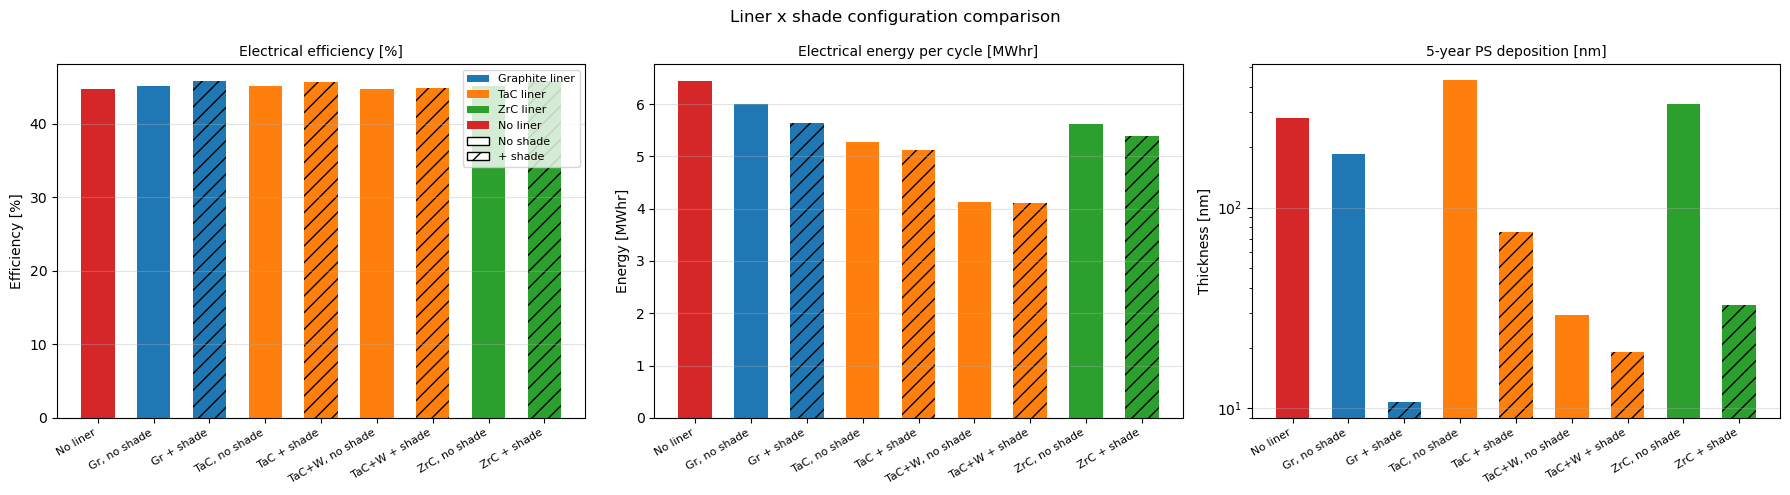

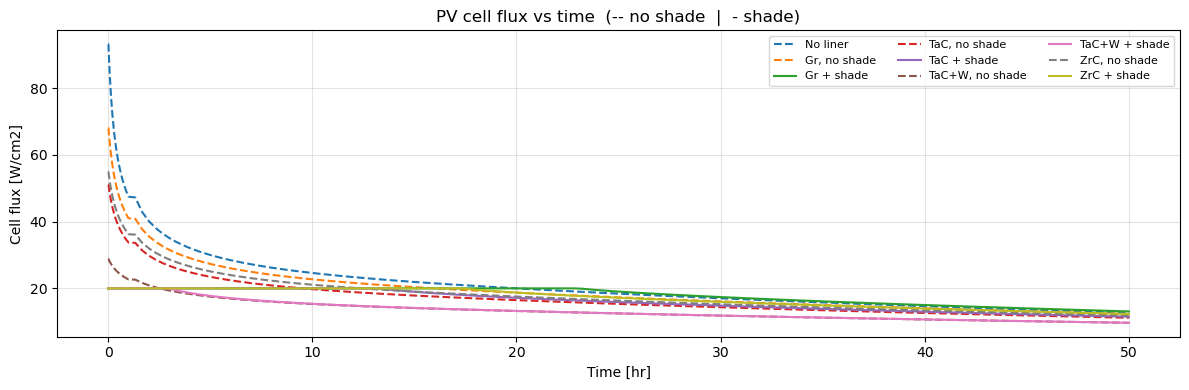

In [ ]:
# -- Scratch: liner x shade configuration comparison --------------------------
# Runs the full discharge simulation for every (liner type) x (shade on/off)
# combination and compares electrical performance and PS deposition.
# NOTE: 9 full simulations -- expect ~9x normal run time.
from thermal.deposition import deposition_rate_tinless as _dep_fn

_S_PER_YR = 3.154e7
_th_w_val  = p.get("tungsten_foil_thickness", 25e-6)

# liner_b, liner_mat, w_foil, shade_b
# shade requires a liner -- no-liner case is always no-shade
_configs = [
    dict(label="No liner",          liner_b=False, liner_mat="graphite", w_foil=False, shade_b=False),
    dict(label="Gr, no shade",      liner_b=True,  liner_mat="graphite", w_foil=False, shade_b=False),
    dict(label="Gr + shade",        liner_b=True,  liner_mat="graphite", w_foil=False, shade_b=True),
    dict(label="TaC, no shade",     liner_b=True,  liner_mat="tac",      w_foil=False, shade_b=False),
    dict(label="TaC + shade",       liner_b=True,  liner_mat="tac",      w_foil=False, shade_b=True),
    dict(label="TaC+W, no shade",   liner_b=True,  liner_mat="tac",      w_foil=True,  shade_b=False),
    dict(label="TaC+W + shade",     liner_b=True,  liner_mat="tac",      w_foil=True,  shade_b=True),
    dict(label="ZrC, no shade",     liner_b=True,  liner_mat="zrc",      w_foil=False, shade_b=False),
    dict(label="ZrC + shade",       liner_b=True,  liner_mat="zrc",      w_foil=False, shade_b=True),
]

def _run_config(liner_b, liner_mat, w_foil, shade_b):
    _block = GraphiteBlock(
        initial_temp_distribution=np.full((num_ax, num_rad), float(T_init)),
        inner_radius=r_in, outer_radius=r_out, length=L, th_ins=th_ins,
    )
    _pipe    = Pipe(OD=0.02, length=L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    _storage = StorageModule(
        N_pipes=1, Pipe=_pipe, Block=_block,
        num_ax_segments=num_ax, num_rad_segments=num_rad, bypass_range=[0, 1],
    )
    _ps = PowerStick(
        axial_steps=num_ax, width=side_len, height=L,
        cooling_temp=T_ps, f_bare=f_bare, f_active=f_active,
        liner_bool=liner_b, liner_width=liner_side_len,
        emissivity_table=emissivity_table,
    )
    if liner_b:
        _d_dep  = r_liner_eff - r_ps_eff
        _ar_dep = r_liner_eff / r_ps_eff
    else:
        _d_dep  = r_in - r_ps_eff
        _ar_dep = r_in / r_ps_eff
    if w_foil:
        _surf = "tungsten"
    elif liner_b and liner_mat == "tac":
        _surf = "tac"
    elif liner_b and liner_mat == "zrc":
        _surf = "zrc"
    else:
        _surf = "graphite"
    _dep_kw = dict(
        T_ps=T_ps, d=_d_dep, area_ratio=_ar_dep, surface_material=_surf,
        th_tac=liner_thickness, th_w=(_th_w_val if w_foil else 0.0),
    )
    _sim = TinlessSimulation(
        _storage, _ps,
        T_sur=T_sur, block_heat_loss=block_heat_loss_bool,
        shade_bool=shade_b,
        shade_side_len=(shade_side_len if shade_b else None),
        shade_thickness=shade_thickness,
        shade_surface_emissivity=shade_surface_emissivity,
        shade_outer_foil=shade_outer_foil,
        shade_num_conduction_layers=shade_num_conduction_layers,
        f_shade_min=(f_shade_min if shade_b else 0.0),
        f_shade_max=(f_shade_max if shade_b else 0.9),
        nominal_cell_flux=(avg_flux if shade_b else None),
        liner_material=liner_mat,
        liner_thickness=liner_thickness,
        liner_tungsten_foil=w_foil,
    )
    return _sim.run_simulation(
        end_time=end_time, dt_short=dt_short, dt_medium=dt_medium, dt_long=dt_long,
        sub_steps=sub_steps, dt_short_duration=dt_short_duration,
        deposition_fn=_dep_fn, deposition_kwargs=_dep_kw,
    )

# -- Run all configs -----------------------------------------------------------
_records = []
for _cfg in _configs:
    print(f"Running: {_cfg['label']} ...", flush=True)
    _res = _run_config(_cfg["liner_b"], _cfg["liner_mat"], _cfg["w_foil"], _cfg["shade_b"])
    _cum_Q = np.trapz(_res["Q_rad"],  _res["time"])
    _cum_P = np.trapz(_res["P_elec"], _res["time"])
    _cycles_per_yr = _S_PER_YR / (2 * _res["time"][-1])
    _records.append({
        "label":       _cfg["label"],
        "shade_b":     _cfg["shade_b"],
        "liner_mat":   _cfg["liner_mat"],
        "E_th_MWhr":   _cum_Q / 3.6e9,
        "E_el_MWhr":   _cum_P / 3.6e9,
        "eff_pct":     _cum_P / _cum_Q * 100,
        "dep_cy_nm":   _res["dep_total_nm"],
        "dep_5yr_nm":  _res["dep_total_nm"] * _cycles_per_yr * 5,
        "dep_30yr_nm": _res["dep_total_nm"] * _cycles_per_yr * 30,
        "res":         _res,
    })
    print(f"  eff={_records[-1]['eff_pct']:.2f}%  "
          f"E_el={_records[-1]['E_el_MWhr']:.3f} MWhr  "
          f"dep/cycle={_res['dep_total_nm']:.3f} nm  "
          f"30-yr={_records[-1]['dep_30yr_nm']:.2f} nm")

# -- Summary table -------------------------------------------------------------
print()
_cols = f"{'Configuration':<22}  {'E_th':>7}  {'E_el':>7}  {'Eff':>6}  {'Dep/cyc':>9}  {'5-yr':>8}  {'30-yr':>8}"
print(_cols)
print('-' * len(_cols))
for _r in _records:
    _sh = 'o' if _r["shade_b"] else '-'
    print(f"{_sh} {_r['label']:<21}  {_r['E_th_MWhr']:>6.3f}  {_r['E_el_MWhr']:>6.3f}  "
          f"{_r['eff_pct']:>5.2f}%  {_r['dep_cy_nm']:>8.3f}nm  "
          f"{_r['dep_5yr_nm']:>6.3f}nm  {_r['dep_30yr_nm']:>6.2f}nm")
print(f"{'':23}  {'MWhr':>7}  {'MWhr':>7}  {'%':>6}  {'nm':>9}  {'nm':>8}  {'nm':>8}")

# -- Bar charts ----------------------------------------------------------------
_labels  = [_r["label"]   for _r in _records]
_x       = np.arange(len(_records))

# Color by material, hatch by shade status
_mat_colors = {"graphite": "C0", "tac": "C1", "zrc": "C2"}
_no_liner_color = "C3"
_colors  = [_mat_colors.get(_r["liner_mat"], _no_liner_color)
            if _r["label"] != "No liner" else _no_liner_color
            for _r in _records]
_hatches = ["//" if _r["shade_b"] else "" for _r in _records]

fig_c, axes_c = plt.subplots(1, 3, figsize=(18, 5))
fig_c.suptitle("Liner x shade configuration comparison", fontsize=12)

_metrics = [
    (axes_c[0], [_r["eff_pct"]     for _r in _records], "Electrical efficiency [%]",         "Efficiency [%]"),
    (axes_c[1], [_r["E_el_MWhr"]   for _r in _records], "Electrical energy per cycle [MWhr]", "Energy [MWhr]"),
    (axes_c[2], [_r["dep_5yr_nm"] for _r in _records], "5-year PS deposition [nm]",         "Thickness [nm]"),
]
for _ax, _vals, _title, _ylabel in _metrics:
    _bars = _ax.bar(_x, _vals, 0.6, color=_colors)
    for _bar, _hatch in zip(_bars, _hatches):
        _bar.set_hatch(_hatch)
    _ax.set_title(_title, fontsize=10)
    _ax.set_ylabel(_ylabel)
    _ax.set_xticks(_x)
    _ax.set_xticklabels(_labels, rotation=30, ha="right", fontsize=8)
    _ax.grid(axis="y", alpha=0.35)

axes_c[2].set_yscale("log")

from matplotlib.patches import Patch
_legend = [
    Patch(facecolor="C0", label="Graphite liner"),
    Patch(facecolor="C1", label="TaC liner"),
    Patch(facecolor="C2", label="ZrC liner"),
    Patch(facecolor="C3", label="No liner"),
    Patch(facecolor="white", edgecolor="black", label="No shade"),
    Patch(facecolor="white", edgecolor="black", hatch="//", label="+ shade"),
]
axes_c[0].legend(handles=_legend, fontsize=8)

plt.tight_layout()
plt.show()

# -- Cell flux vs time overlay -------------------------------------------------
_A_cell_cm2 = 4 * side_len * L * (1 - f_bare) * f_active * 1e4
fig_p, ax_p = plt.subplots(figsize=(12, 4))
for _r in _records:
    _ls = "-" if _r["shade_b"] else "--"
    ax_p.plot(_r["res"]["time"] / 3600, _r["res"]["Q_cell"] / _A_cell_cm2,
              label=_r["label"], linestyle=_ls)
ax_p.set_xlabel("Time [hr]")
ax_p.set_ylabel("Cell flux [W/cm2]")
ax_p.set_title("PV cell flux vs time  (-- no shade  |  - shade)")
ax_p.legend(fontsize=8, ncol=3)
ax_p.grid(True, alpha=0.35)
fig_p.tight_layout()
plt.show()


Running 36 cases  (liner_sz × T_min × avg_flux = 4×3×3) ...
[discharge] T_avg=2073 K reached cutoff 2073 K at t=48.1667 hr (173400.0 s) — powerstick removed, conduction-only phase begins.
  [ 1/36] sz=1.00x  T_min=1800°C  flux=10 W/cm²  η=45.23%  dep30=0.003 μm
[discharge] T_avg=2072 K reached cutoff 2073 K at t=59.3333 hr (213600.0 s) — powerstick removed, conduction-only phase begins.
  [ 2/36] sz=1.00x  T_min=1800°C  flux=15 W/cm²  η=45.57%  dep30=0.018 μm
  [ 3/36] sz=1.00x  T_min=1800°C  flux=20 W/cm²  η=45.56%  dep30=0.040 μm
[discharge] T_avg=2173 K reached cutoff 2173 K at t=47.0000 hr (169200.0 s) — powerstick removed, conduction-only phase begins.
  [ 4/36] sz=1.00x  T_min=1900°C  flux=10 W/cm²  η=45.28%  dep30=0.004 μm
[discharge] T_avg=2171 K reached cutoff 2173 K at t=52.1667 hr (187800.0 s) — powerstick removed, conduction-only phase begins.
  [ 5/36] sz=1.00x  T_min=1900°C  flux=15 W/cm²  η=45.76%  dep30=0.027 μm
[discharge] T_avg=2172 K reached cutoff 2173 K at t=66.666

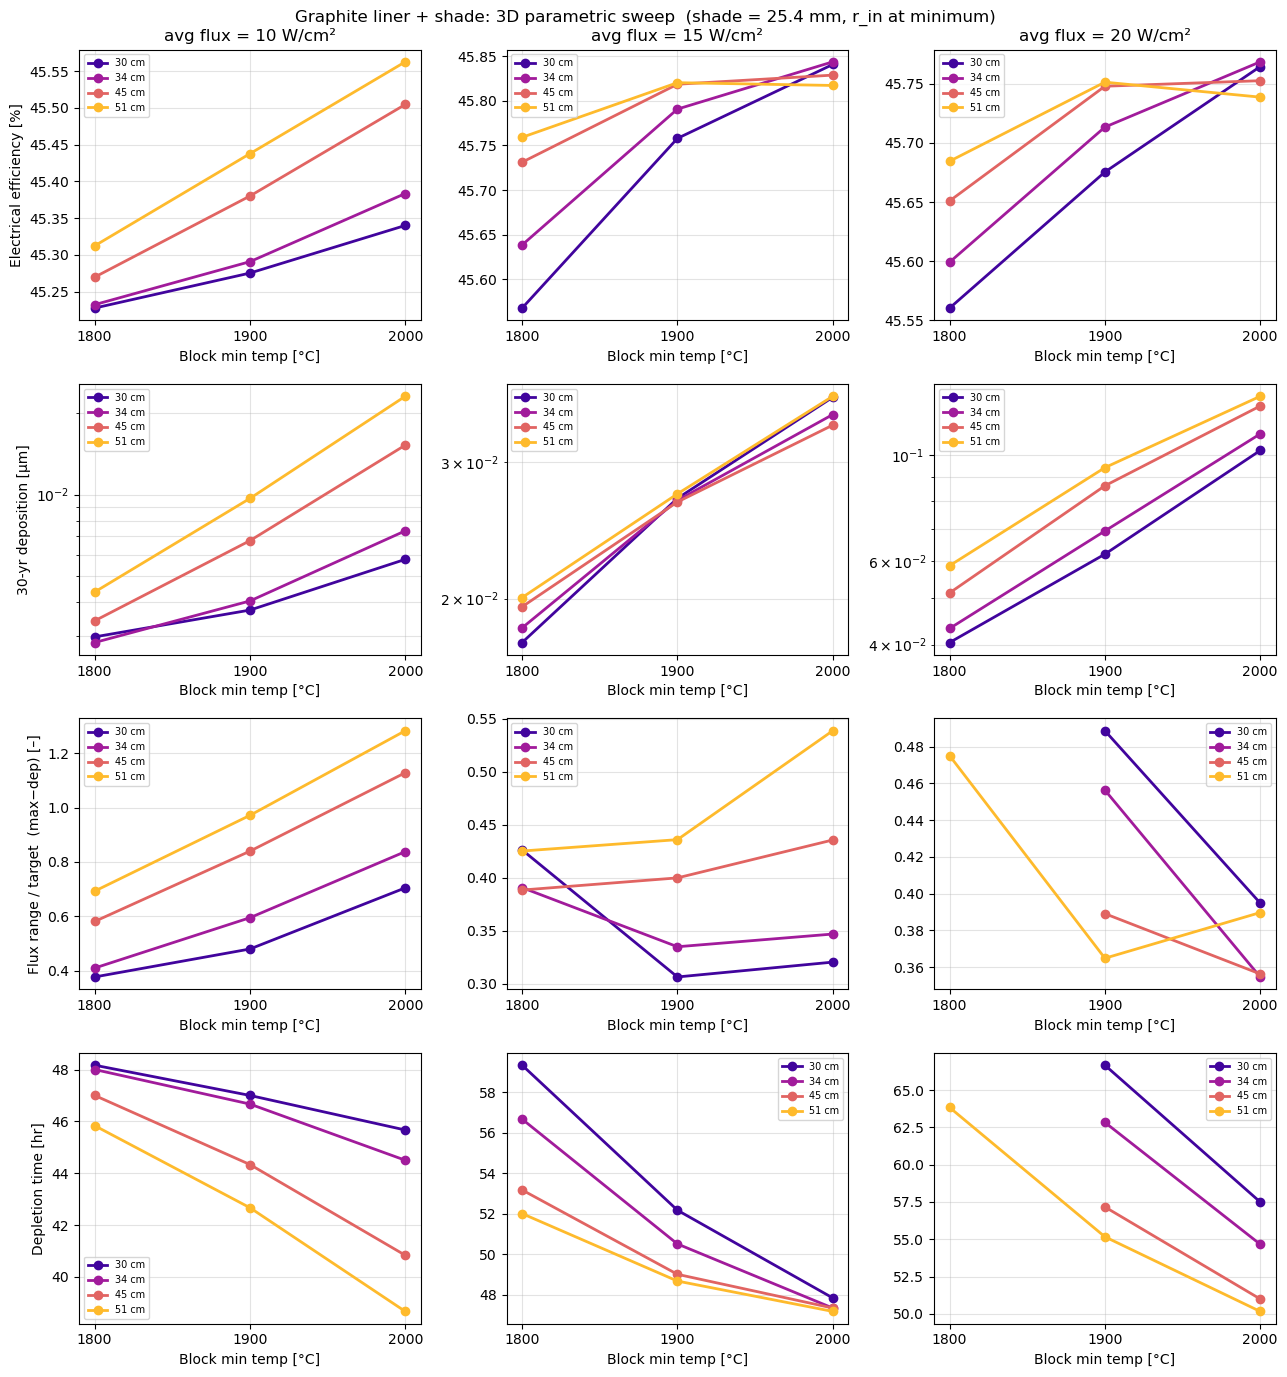

In [ ]:
# -- Parametric sweep: graphite liner + shade ----------------------------------
# 3D sweep over liner size, block minimum temperature, and average cell flux.
# Shade thickness fixed at 25.4 mm (1 inch). r_in fixed at minimum feasible.
from thermal.deposition import deposition_rate_tinless as _dep_fn
import itertools

_S_PER_YR = 3.154e7

# ── Load inputs from YAML ───────────────────────────────────────────────────────────────────────
with open('tinless_model_input.yaml') as _f:
    _cfg = yaml.safe_load(_f)
_s = _cfg['storage']
_p = _cfg['powerstick']
_sh = _cfg.get('shade', {})

end_time             = _cfg['end_time']
T_sur                = _cfg['T_sur']
block_heat_loss_bool = _cfg['block_heat_loss_bool']
dt_medium         = _cfg['dt_medium']
dt_long           = _cfg['dt_long']
dt_short_duration = _cfg.get('dt_short_duration', 3600)
sub_steps         = _cfg['sub_steps']

avg_flux         = _s['avg_flux']
duration_hr      = _s['duration_hr']
T_min            = _s['T_min']
block_temp_range = _s['block_temp_range']
L                = _s['L']
th_ins           = _s['th_ins']
num_ax           = _s['num_ax_segments']
num_rad          = _s['num_rad_segments']

side_len       = _p['side_len']
area_ratio     = _p['area_ratio']
f_bare         = _p['f_bare']
f_active       = _p['f_active']
T_ps           = _p['cooling_temp']
liner_side_len = _p['liner_side_len']

corner_gap                   = _sh.get('corner_gap', 0.003175)
shade_surface_emissivity     = _sh.get('surface_emissivity', 0.8)
shade_outer_foil             = _sh.get('outer_foil', False)
shade_num_conduction_layers  = _sh.get('num_conduction_layers', 5)

raw_emis = _cfg['emissivity_tables'][0]['value']
emissivity_table = [(tuple(row[0]), float(row[1]), float(row[2]), float(row[3]))
                    for row in raw_emis]

r_ps_eff    = 2 * side_len / np.pi
r_liner_eff = 2 * liner_side_len / np.pi
r_in        = r_ps_eff * area_ratio
A_ps        = 4 * side_len * L
T_avg_      = T_min + block_temp_range / 2
f_cell_     = (1.0 - f_bare) * f_active
f_inact_    = (1.0 - f_bare) * (1.0 - f_active)
_ps_tmp     = PowerStick(axial_steps=1, width=side_len, height=L,
                         cooling_temp=T_ps, f_bare=f_bare, f_active=f_active,
                         liner_bool=True, liner_width=liner_side_len,
                         emissivity_table=emissivity_table)
_inc_bins, _, _ = _ps_tmp.incident_energy(T_min - 100, 1 / area_ratio)
_inc_tot    = sum(_inc_bins.values())
f_Q_        = sum(
    _inc_bins[row[0]] / _inc_tot * f_cell_ * row[1]
    / (f_bare * row[2] + f_cell_ * row[1] + f_inact_ * row[3])
    for row in emissivity_table)
E_req       = avg_flux * 1e4 * A_ps * f_cell_ / f_Q_ * duration_hr * 3600
e_dens      = storage_rho(T_avg_) * storage_cp(T_avg_) * block_temp_range
V_block     = E_req / e_dens
r_out       = np.sqrt(V_block / (np.pi * L) + r_in**2)

# ── sweep ranges ────────────────────────────────────────────────────────────────────────────────────────
_liner_sz_factors = [1.00, 1.15, 1.50, 1.70]   # scale on liner_side_len / r_liner_eff
_T_min_C_vals     = [1800, 1900, 2000]           # block minimum (cutoff) temperature [C]
_avg_flux_vals    = [10, 15, 20]                 # nominal cell flux [W/cm²]
_SHADE_TH_FIXED   = 25.4e-3                      # shade thickness fixed at 1 inch = 25.4 mm
_LINER_TH_FIXED   = 0.01                         # liner wall thickness fixed at 1 cm
_R_IN_F_FIXED     = 1.01                         # r_in safety margin on liner clearance

def _run_gr_shade(liner_sz_f=1.0, T_min_K=None, avg_flux_Wcm2=None):
    _T_min    = T_min_K             if T_min_K       is not None else T_min
    _avg_flux = avg_flux_Wcm2 if avg_flux_Wcm2 is not None else avg_flux

    _shade_th = _SHADE_TH_FIXED
    _l_sz     = liner_side_len * liner_sz_f
    _r_lin    = r_liner_eff    * liner_sz_f

    # Shade at minimum physically-valid position for this liner.
    _r_shade_new  = (1.0 + np.sqrt(2) / 2.0) * _r_lin
    _shade_sl_new = _r_shade_new * np.pi / 2.0

    # f_shade limits for this shade geometry.
    _shade_perim = 4.0 * _shade_sl_new
    _f_shade_min = 8.0 * _shade_th / _shade_perim
    _f_shade_max = 1.0 - 8.0 * corner_gap / _shade_perim

    # Block sized for this case: r_in from liner geometry, r_out from energy balance.
    _r_in_use    = _R_IN_F_FIXED * (1.0 + np.sqrt(2)) * _r_lin
    _T_avg_case  = _T_min + block_temp_range / 2
    _E_req_case  = _avg_flux * 1e4 * A_ps * f_cell_ / f_Q_ * duration_hr * 3600
    _e_dens_case = storage_rho(_T_avg_case) * storage_cp(_T_avg_case) * block_temp_range
    _r_out_use   = np.sqrt(_E_req_case / _e_dens_case / (np.pi * L) + _r_in_use**2)

    _block = GraphiteBlock(
        initial_temp_distribution=np.full((num_ax, num_rad), float(_T_min + 500.0)),
        inner_radius=_r_in_use, outer_radius=_r_out_use, length=L, th_ins=th_ins,
    )
    _pipe    = Pipe(OD=0.02, length=L, wall_thickness=0.001, roughness=1e-5, th_ins=0.0)
    _storage = StorageModule(
        N_pipes=1, Pipe=_pipe, Block=_block,
        num_ax_segments=num_ax, num_rad_segments=num_rad, bypass_range=[0, 1],
    )
    _ps = PowerStick(
        axial_steps=num_ax, width=side_len, height=L,
        cooling_temp=T_ps, f_bare=f_bare, f_active=f_active,
        liner_bool=True, liner_width=_l_sz,
        emissivity_table=emissivity_table,
    )
    _dep_kw = dict(
        T_ps=T_ps, d=_r_lin - r_ps_eff,
        area_ratio=(1.0 + np.sqrt(2)) * _r_lin / r_ps_eff,
        surface_material='graphite', th_tac=0.0, th_w=0.0,
    )
    _sim = TinlessSimulation(
        _storage, _ps,
        T_sur=T_sur, block_heat_loss=block_heat_loss_bool,
        shade_bool=True,
        shade_side_len=_shade_sl_new,
        shade_thickness=_shade_th,
        shade_surface_emissivity=shade_surface_emissivity,
        shade_outer_foil=shade_outer_foil,
        shade_num_conduction_layers=shade_num_conduction_layers,
        f_shade_min=_f_shade_min,
        f_shade_max=_f_shade_max,
        nominal_cell_flux=_avg_flux,
        liner_material='graphite',
        liner_thickness=_LINER_TH_FIXED,
        liner_tungsten_foil=False,
    )
    # Cap sweep end_time at 2x duration_hr so slow-discharge cases return NaN quickly.
    #_sweep_end = min(end_time, 2 * duration_hr * 3600)
    _sweep_end = end_time
    _res = _sim.run_simulation(
        end_time=_sweep_end, dt_short=dt_medium, dt_medium=dt_medium, dt_long=dt_long,
        sub_steps=sub_steps, dt_short_duration=dt_short_duration,
        deposition_fn=_dep_fn, deposition_kwargs=_dep_kw,
        T_ps_cutoff=_T_min,
        stop_at_cutoff=True,
    )
    _cum_Q  = np.trapz(_res['Q_rad'],  _res['time'])
    _cum_P  = np.trapz(_res['P_elec'], _res['time'])
    _cyc_yr = _S_PER_YR / (2 * _res['time'][-1])
    _t_ps     = _res.get('t_ps_removed')
    _A_active = 4 * side_len * L * f_active
    _flux_arr = np.array(_res['Q_cell']) / _A_active / 1e4
    if _t_ps is not None:
        _idx_dep      = max(0, np.searchsorted(_res['time'], _t_ps, side='right') - 1)
        _flux_dep     = float(_flux_arr[_idx_dep])
        _flux_max     = float(np.nanmax(_flux_arr))
        _flux_rng_rel = (_flux_max - _flux_dep) / _avg_flux
        _t_dep_hr     = _t_ps / 3600.0
    else:
        _flux_rng_rel = float('nan')
        _t_dep_hr     = float('nan')
    return {
        'eff_pct':        _cum_P / _cum_Q * 100,
        'dep_30yr_nm':    _res['dep_total_nm'] * _cyc_yr * 30,
        'flux_range_rel': _flux_rng_rel,
        't_dep_hr':       _t_dep_hr,
    }

# ── run 3D sweep (36 cases) ───────────────────────────────────────────────────────────────────────────────────────
_cases = list(itertools.product(
    enumerate(_liner_sz_factors),
    enumerate(_T_min_C_vals),
    enumerate(_avg_flux_vals),
))
_n = len(_cases)
print(f'Running {_n} cases  '
      f'(liner_sz × T_min × avg_flux = '
      f'{len(_liner_sz_factors)}×{len(_T_min_C_vals)}×{len(_avg_flux_vals)}) ...', flush=True)

_results_3d = {}   # keyed by (i_sz, i_tm, i_fl)
for _k, ((i_sz, _sz_f), (i_tm, _tm_C), (i_fl, _fl)) in enumerate(_cases):
    _r = _run_gr_shade(liner_sz_f=_sz_f, T_min_K=_tm_C + 273.15, avg_flux_Wcm2=_fl)
    _results_3d[(i_sz, i_tm, i_fl)] = _r
    print(f'  [{_k+1:2d}/{_n}] sz={_sz_f:.2f}x  T_min={_tm_C:.0f}°C  flux={_fl:.0f} W/cm²  '
          f'η={_r["eff_pct"]:.2f}%  dep30={_r["dep_30yr_nm"]:.3f} nm', flush=True)

# ── plots ────────────────────────────────────────────────────────────────────────────────────────────────
# rows = [efficiency, deposition, P at depletion, depletion time]
# cols = avg_flux panels, lines = liner_sz, x-axis = T_min_C
import matplotlib.cm as cm

_sz_colors = cm.plasma(np.linspace(0.1, 0.85, len(_liner_sz_factors)))
_fig, _axes = plt.subplots(4, 3, figsize=(13, 14))
_fig.suptitle(
    'Graphite liner + shade: 3D parametric sweep  '
    '(shade = 25.4 mm, r_in at minimum)',
    fontsize=12,
)

for col, (i_fl, _fl) in enumerate(zip(range(len(_avg_flux_vals)), _avg_flux_vals)):
    ax_e  = _axes[0, col]
    ax_d  = _axes[1, col]
    ax_en = _axes[2, col]
    ax_pk = _axes[3, col]

    for i_sz, (_sz_f, _col) in enumerate(zip(_liner_sz_factors, _sz_colors)):
        _effs  = [_results_3d[(i_sz, i_tm, i_fl)]['eff_pct']     for i_tm in range(len(_T_min_C_vals))]
        _deps  = [_results_3d[(i_sz, i_tm, i_fl)]['dep_30yr_um'] for i_tm in range(len(_T_min_C_vals))]
        _franges = [_results_3d[(i_sz, i_tm, i_fl)]['flux_range_rel'] for i_tm in range(len(_T_min_C_vals))]
        _tdeps   = [_results_3d[(i_sz, i_tm, i_fl)]['t_dep_hr']       for i_tm in range(len(_T_min_C_vals))]
        _lbl     = f'{liner_side_len * _sz_f * 100:.0f} cm'
        ax_e.plot( _T_min_C_vals, _effs,   'o-', color=_col, lw=2, label=_lbl)
        ax_d.plot( _T_min_C_vals, _deps,   'o-', color=_col, lw=2, label=_lbl)
        ax_en.plot(_T_min_C_vals, _franges, 'o-', color=_col, lw=2, label=_lbl)
        ax_pk.plot(_T_min_C_vals, _tdeps,  'o-', color=_col, lw=2, label=_lbl)

    ax_e.set_title(f'avg flux = {_fl} W/cm²')
    for _ax in (ax_e, ax_d, ax_en, ax_pk):
        _ax.set_xlabel('Block min temp [°C]')
        _ax.set_xticks(_T_min_C_vals)
        _ax.grid(True, alpha=0.35)
        _ax.legend(fontsize=7)
    ax_d.set_yscale('log')
    ax_d.grid(True, alpha=0.35, which='both')
    if col == 0:
        ax_e.set_ylabel('Electrical efficiency [%]')
        ax_d.set_ylabel('30-yr deposition [μm]')
        ax_en.set_ylabel('Flux range / target  (max−dep) [–]')
        ax_pk.set_ylabel('Depletion time [hr]')

plt.tight_layout()
plt.show()


0.44999999999999996
